## **Nama : Zalsabilah Nurdin**
## **Nim : H061241001**
## **Tugas Perencanaan Prompt AI untuk Bidang Geofisika**


## Prompt 1 — Inversi 1D Geolistrik Schlumberger untuk Akuifer Air Tanah

**Role:**
kita adalah seorang geofisikawan hidrogeologi berpengalaman yang menguasai akuisisi dan inversi data geolistrik resistivitas konfigurasi Schlumberger.

**Task:**
Interpretasikan data Vertical Electrical Sounding (VES) pada satu titik sounding untuk menentukan jumlah lapisan, ketebalan, dan nilai resistivitas tiap lapisan, lalu tentukan lapisan yang paling berpotensi sebagai akuifer. Jelaskan alasan pemilihan model lapisan secara naratif.

**Context:**
Survei dilakukan di daerah dataran aluvial untuk mencari sumber air tanah bagi desa yang kesulitan air bersih. Geologi regional diperkirakan berupa perlapisan lempung, pasir, dan batuan dasar yang lebih kompak. Hasil interpretasi akan dipakai sebagai bahan pertimbangan awal penentuan titik pengeboran.

**Input:**
Tabel data VES berisi spasi elektroda AB/2 (m), spasi MN/2 (m), arus (mA), beda potensial (mV), dan nilai resistivitas semu (ohm.m). Bila tersedia, sertakan log bor terdekat sebagai pembanding.

**Constraints:**
- Gunakan hanya data yang diberikan; jangan mengarang nilai pengukuran.
- Sebutkan asumsi model (misalnya lapisan horizontal homogen isotropik).
- Bila terdapat prinsip ekuivalensi, nyatakan bahwa solusi tidak tunggal.
- Jangan menyimpulkan debit atau kualitas air, karena data tidak cukup untuk itu.
- Gunakan bahasa Indonesia dengan istilah teknis dalam bahasa Inggris seperti aslinya.

**Output:**

(1) Ringkasan kualitas data dan titik outlier. 

(2) Deskripsi kurva resistivitas semu terhadap AB/2. 

(3) Tabel model lapisan (resistivitas, ketebalan, kedalaman). 

(4) Interpretasi litologi tiap lapisan dan lapisan target akuifer. 

(5) Keterbatasan dan ketidakpastian. 

(6) Rekomendasi tindak lanjut, misalnya penambahan titik VES.

**Quality criteria:**
Model harus konsisten dengan data (RMS error dilaporkan), interpretasi litologi sesuai kisaran resistivitas umum, ketidakpastian dinyatakan eksplisit, dan tiap klaim dapat ditelusuri ke data input.

**Optional verification:**
Bila diperlukan, bandingkan model dengan log bor terdekat, lalu tandai bagian yang tidak cocok. Jika data tidak memadai untuk inversi, hentikan dan jelaskan data tambahan yang dibutuhkan.

Input  : tabel VES (AB/2, MN/2, arus mA, beda potensial mV) -> rho_a = K * dV / I
         + log bor terdekat (opsional)

        
Model  : 3 lapisan horizontal, homogen, isotropik (asumsi)


Inversi: random search + refinement (tanpa fungsi def), forward model integral Hankel numerik


Output : (1) kualitas data & outlier  (2) deskripsi kurva  (3) tabel model
         (4) litologi & target akuifer (5) keterbatasan      (6) rekomendasi

=== TABEL DATA VES ===
 AB/2  MN/2  I_mA  dV_mV  K (m)  rho_a (ohm.m)
  1.5   0.5    50 318.45    6.3          40.02
  2.0   0.5    50 163.70   11.8          38.57
  3.0   0.5    50  67.60   27.5          37.17
  4.0   0.5    50  35.24   49.5          34.87
  6.0   0.5    50  11.78  112.3          26.46
  8.0   0.5    50   5.33  200.3          21.35
 10.0   0.5   100   6.13  313.4          19.21
 15.0   5.0   100  25.45   62.8          15.99
 20.0   5.0   100  13.50  117.8          15.90
 30.0   5.0   150  14.76  274.9          27.05
 40.0   5.0   150   7.18  494.8          23.68
 60.0   5.0   200   5.63 1123.1          31.62
 80.0   5.0   200   3.90 2002.8          39.05
100.0   5.0   200   2.67 3133.7          41.84
150.0   5.0   300   2.22 7060.7          52.25

=== (1) KUALITAS DATA ===
Jumlah titik ukur : 15
Rentang AB/2      : 1.5 - 150.0 m
Rentang rho_a     : 15.9 - 52.2 ohm.m
Titik diduga outlier (AB/2, m): [30.]
Kriteria outlier: simpangan log10(rho_a) terhadap rata-rata tetan

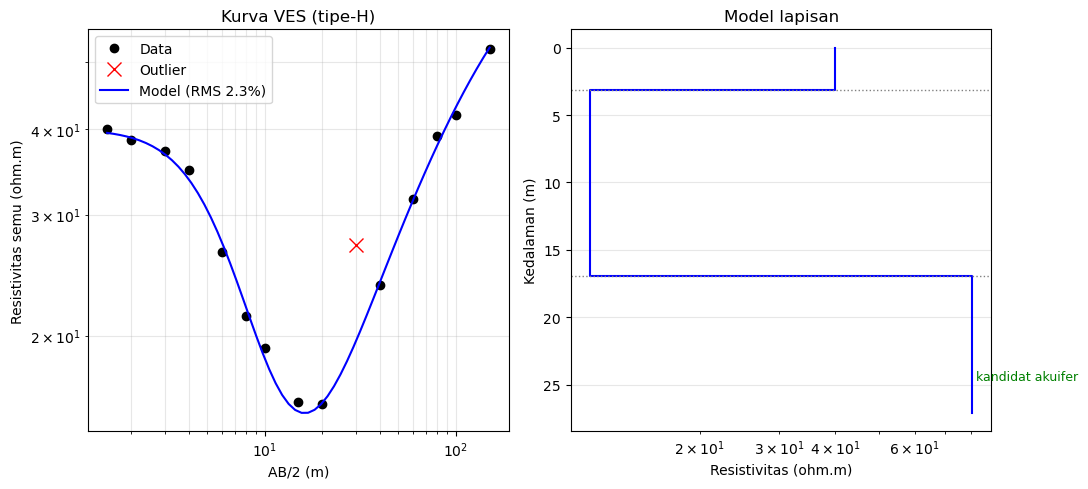

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import j1

np.random.seed(42)

data = pd.DataFrame({
    "AB/2": [1.5, 2, 3, 4, 6, 8, 10, 15, 20, 30, 40, 60, 80, 100, 150],
    "MN/2": [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 5, 5, 5, 5, 5, 5, 5, 5],
    "I_mA": [50, 50, 50, 50, 50, 50, 100, 100, 100, 150, 150, 200, 200, 200, 300],
    "dV_mV": [318.45, 163.7, 67.6, 35.24, 11.78, 5.33, 6.13, 25.45, 13.5,
              14.76, 7.18, 5.63, 3.9, 2.67, 2.22]})

log_bor = None
# log_bor = [(0, 3, "pasir"), (3, 17, "lempung"), (17, 40, "pasir")]


# PEMERIKSAAN KECUKUPAN DATA (hentikan jika tidak memadai)
kolom_wajib = ["AB/2", "MN/2", "I_mA", "dV_mV"]
kurang = [k for k in kolom_wajib if k not in data.columns]
if len(kurang) > 0:
    raise SystemExit("Data tidak memadai: kolom berikut belum ada -> %s" % kurang)
data = data.dropna(subset=kolom_wajib)
if (data["I_mA"] <= 0).any() or (data["MN/2"] >= data["AB/2"]).any():
    raise SystemExit("Data tidak valid: arus <= 0 atau MN/2 >= AB/2. Periksa tabel input.")
if len(data) < 8:
    raise SystemExit("Data tidak memadai untuk inversi 3 lapisan (< 8 titik AB/2). Tambahkan titik pengukuran.")
if data["AB/2"].max() / data["AB/2"].min() < 20:
    raise SystemExit("Rentang AB/2 terlalu sempit (< 20x) untuk menembus 3 lapisan. Perbesar bentangan AB/2.")

data = data.sort_values("AB/2").reset_index(drop=True)
ab2 = data["AB/2"].values.astype(float)
mn2 = data["MN/2"].values.astype(float)

# Faktor geometri Schlumberger & resistivitas semu
K = np.pi * (ab2**2 - mn2**2) / (2 * mn2)                  # m
rhoa = K * data["dV_mV"].values / data["I_mA"].values      # ohm.m  (mV/mA = ohm)
data["K (m)"] = K.round(1)
data["rho_a (ohm.m)"] = rhoa.round(2)

# Konstanta forward model
lam = np.logspace(-4, 1, 6000)
dln = np.log(lam[1] / lam[0])


# (1) KUALITAS DATA & OUTLIER
logr = np.log10(rhoa)
res_smooth = np.zeros(len(rhoa))
for i in range(1, len(rhoa) - 1):
    res_smooth[i] = logr[i] - 0.5 * (logr[i - 1] + logr[i + 1])
outlier = np.abs(res_smooth) > 0.12
print("=== TABEL DATA VES ===")
print(data.to_string(index=False))
print("\n=== (1) KUALITAS DATA ===")
print("Jumlah titik ukur : %d" % len(rhoa))
print("Rentang AB/2      : %.1f - %.1f m" % (ab2.min(), ab2.max()))
print("Rentang rho_a     : %.1f - %.1f ohm.m" % (rhoa.min(), rhoa.max()))
print("Titik diduga outlier (AB/2, m):", ab2[outlier] if outlier.any() else "tidak ada")
print("Kriteria outlier: simpangan log10(rho_a) terhadap rata-rata tetangga > 0.12")

ab2_u = ab2[~outlier]
rho_u = rhoa[~outlier]
J_u = j1(np.outer(ab2_u, lam)) * lam**2 * dln


# INVERSI
# parameter tiap model: [rho1, rho2, rho3, h1, h2]
allp = np.empty((0, 5))
allrms = np.empty(0)
M = 4000
P = np.column_stack([
    10 ** np.random.uniform(0, 3.3, M), 10 ** np.random.uniform(0, 3.3, M),
    10 ** np.random.uniform(0, 3.3, M), 10 ** np.random.uniform(0, 1.5, M),
    10 ** np.random.uniform(0, 1.8, M)])
for ronde in range(8):
    if ronde > 0:
        sigma = 0.35 * (0.6 ** ronde)
        P = best * np.exp(np.random.normal(0, sigma, (1500, 5)))
        P[:, 3:] = np.clip(P[:, 3:], 0.3, None)
    t2 = np.tanh(np.outer(P[:, 4], lam))
    T2 = (P[:, [2]] + P[:, [1]] * t2) / (1 + P[:, [2]] * t2 / P[:, [1]])
    t1 = np.tanh(np.outer(P[:, 3], lam))
    T1 = (T2 + P[:, [0]] * t1) / (1 + T2 * t1 / P[:, [0]])
    calc = P[:, [0]] + ab2_u**2 * ((T1 - P[:, [0]]) @ J_u.T)
    rms = np.sqrt(np.mean(((rho_u - calc) / rho_u) ** 2, axis=1)) * 100
    allp = np.vstack([allp, P])
    allrms = np.concatenate([allrms, rms])
    best = allp[np.argmin(allrms)]

rms_best = allrms.min()
r1, r2, r3, h1, h2 = best
rho_lap = [r1, r2, r3]

#RMS <= 1.2 x RMS 
ekiv = allp[allrms <= max(rms_best * 1.2, rms_best + 1.0)]


# (2) DESKRIPSI KURVA rho_a vs AB/2
print("\n=== (2) DESKRIPSI KURVA rho_a vs AB/2 ===")
imin = np.argmin(rho_u)
imax = np.argmax(rho_u)
print("Rho_a awal  (AB/2=%.1f m): %.1f ohm.m" % (ab2_u[0], rho_u[0]))
print("Minimum     (AB/2=%.1f m): %.1f ohm.m" % (ab2_u[imin], rho_u[imin]))
print("Maksimum    (AB/2=%.1f m): %.1f ohm.m" % (ab2_u[imax], rho_u[imax]))
print("Rho_a akhir (AB/2=%.1f m): %.1f ohm.m" % (ab2_u[-1], rho_u[-1]))

# Tipe kurva 3 lapisan dari urutan resistivitas model
if r1 > r2 and r2 < r3:
    tipe = "H"
    ket = "rho1 > rho2 < rho3: lapisan konduktif di antara dua lapisan lebih resistif"
elif r1 < r2 and r2 < r3:
    tipe = "A"
    ket = "rho1 < rho2 < rho3: resistivitas naik terhadap kedalaman"
elif r1 < r2 and r2 > r3:
    tipe = "K"
    ket = "rho1 < rho2 > rho3: lapisan tengah paling resistif"
else:
    tipe = "Q"
    ket = "rho1 > rho2 > rho3: resistivitas turun terhadap kedalaman"
print("Tipe kurva (model 3 lapisan): tipe-%s -> %s" % (tipe, ket))


# (3) TABEL MODEL LAPISAN
tabel = pd.DataFrame({
    "Lapisan": [1, 2, 3],
    "Resistivitas (ohm.m)": [r1, r2, r3],
    "Ketebalan (m)": [round(h1, 2), round(h2, 2), "tak terhingga (half-space)"],
    "Kedalaman atas (m)": [0, round(h1, 2), round(h1 + h2, 2)],
    "Kedalaman bawah (m)": [round(h1, 2), round(h1 + h2, 2), "tak terhingga"]})
tabel["Resistivitas (ohm.m)"] = tabel["Resistivitas (ohm.m)"].round(2)
print("\n=== (3) MODEL LAPISAN (asumsi: horizontal, homogen, isotropik) ===")
print(tabel.to_string(index=False))
print("RMS error model terbaik: %.2f %%" % rms_best)
print("Jumlah model ekuivalen (RMS <= 1.2x terbaik): %d" % len(ekiv))
nama = ["rho1 (ohm.m)", "rho2 (ohm.m)", "rho3 (ohm.m)", "h1 (m)", "h2 (m)"]
for k in range(5):
    print("  Rentang ekuivalen %-13s: %.1f - %.1f" % (nama[k], ekiv[:, k].min(), ekiv[:, k].max()))
print("Catatan: solusi TIDAK tunggal (prinsip ekuivalensi); gunakan rentang di atas, bukan satu nilai pasti.")
print("Catatan: ketebalan lapisan 3 tidak dapat ditentukan (tidak ada lapisan di bawahnya dalam model).")


# (4) INTERPRETASI LITOLOGI & TARGET AKUIFER
print("\n=== (4) INTERPRETASI LITOLOGI (kisaran resistivitas umum) ===")
lit = []
for i in range(3):
    r = rho_lap[i]
    if r < 10:
        teks = "lempung / material jenuh air bersalinitas tinggi"
    elif r < 30:
        teks = "lempung / lempung pasiran"
    elif r < 150:
        teks = "pasir lempungan hingga pasir-kerikil"
    elif r < 500:
        teks = "pasir-kerikil kering atau batuan lapuk"
    else:
        teks = "batuan dasar kompak"
    if i == 0 and 30 <= r < 150:
        teks += " (lapisan penutup, kemungkinan sebagian tak jenuh)"
    lit.append(teks)
    print("Lapisan %d (%.1f ohm.m): %s" % (i + 1, r, teks))

print("\nTarget akuifer:")
target = []
for i in range(1, 3):                       # lapisan 2 dan 3
    if 30 <= rho_lap[i] < 150:
        target.append(i + 1)
if len(target) > 0:
    for t in target:
        print("- Lapisan %d (%.1f ohm.m) berpotensi sebagai akuifer (resistivitas khas pasir jenuh)." % (t, rho_lap[t - 1]))
        if t == 3:
            print("  Ambiguitas: lapisan 3 adalah half-space dengan ketebalan tak diketahui. Resistivitas ini juga dapat")
            print("  mewakili batuan lapuk/ batuan dasar terpecah; belum dapat dipastikan sebagai pasir jenuh air.")
        if t == 2:
            print("  Catatan: lapisan 2 berada di bawah lapisan penutup (h1 = %.1f m)." % h1)
    if r2 < 30 and 3 in target:
        print("  Lapisan 3 berada di bawah lapisan konduktif (lempung) -> kemungkinan akuifer tertekan (confined);")
        print("  bagian atas lapisan 3 baru tercapai pada kedalaman sekitar %.1f m (rentang ekuivalen %.1f - %.1f m)." % (
            h1 + h2, (ekiv[:, 3] + ekiv[:, 4]).min(), (ekiv[:, 3] + ekiv[:, 4]).max()))
else:
    print("- Tidak ada lapisan dengan resistivitas khas akuifer pasir (30-150 ohm.m); perlu log bor atau data tambahan.")
print("Catatan: debit dan kualitas air TIDAK dapat disimpulkan dari data ini.")


# VERIFIKASI DENGAN LOG BOR (opsional)
print("\n=== VERIFIKASI LOG BOR ===")
if log_bor is None:
    print("Log bor tidak tersedia -> verifikasi dilewati. Interpretasi litologi belum terkalibrasi.")
else:
    batas_atas = [0, h1, h1 + h2]
    batas_bawah = [h1, h1 + h2, 1e9]
    for (za, zb, jenis) in log_bor:
        zt = 0.5 * (za + zb)
        idx = 2
        for i in range(3):
            if batas_atas[i] <= zt < batas_bawah[i]:
                idx = i
        r = rho_lap[idx]
        if r < 30:
            kelas = "lempung"
        elif r < 150:
            kelas = "pasir"
        else:
            kelas = "batuan"
        status = "COCOK" if kelas == jenis else "TIDAK COCOK"
        print("Log %.1f-%.1f m (%s) vs model lapisan %d (%.1f ohm.m -> %s): %s" % (za, zb, jenis, idx + 1, r, kelas, status))


# (5) KETERBATASAN & KETIDAKPASTIAN
print("\n=== (5) KETERBATASAN & KETIDAKPASTIAN ===")
print("- Model 3 lapisan horizontal, homogen, isotropik; variasi lateral (2D/3D) tidak terwakili.")
print("- Prinsip ekuivalensi: rho dan ketebalan lapisan tidak unik (lihat rentang ekuivalen).")
print("- Rentang resistivitas tiap litologi saling tumpang tindih (mis. lempung vs pasir bersalinitas tinggi).")
print("- Jumlah lapisan diasumsikan 3; model dengan jumlah lapisan lain belum diuji.")
print("- Titik outlier dikeluarkan dari inversi: AB/2 =", ab2[outlier] if outlier.any() else "tidak ada")


print("\n=== (6) REKOMENDASI ===")
print("- Tambah 2-3 titik VES di sekitar titik ini untuk memeriksa kontinuitas lateral.")
print("- Ulang pengukuran pada AB/2 yang terdeteksi outlier.")
print("- Bandingkan dengan log bor/ sumur warga terdekat untuk mengkalibrasi litologi.")
print("- Uji pumping dan analisis kimia air pada sumur uji untuk menilai debit dan kualitas air.")


t2 = np.tanh(lam * h2)
T2 = (r3 + r2 * t2) / (1 + r3 * t2 / r2)
t1 = np.tanh(lam * h1)
T1 = (T2 + r1 * t1) / (1 + T2 * t1 / r1)
ab_f = np.logspace(np.log10(ab2.min()), np.log10(ab2.max()), 60)
Jf = j1(np.outer(ab_f, lam)) * lam**2 * dln
calc_f = r1 + ab_f**2 * ((T1 - r1) @ Jf.T)

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].loglog(ab2_u, rho_u, "ko", label="Data")
if outlier.any():
    ax[0].loglog(ab2[outlier], rhoa[outlier], "rx", ms=10, label="Outlier")
ax[0].loglog(ab_f, calc_f, "b-", label="Model (RMS %.1f%%)" % rms_best)
ax[0].set_xlabel("AB/2 (m)"); ax[0].set_ylabel("Resistivitas semu (ohm.m)")
ax[0].grid(True, which="both", alpha=.3); ax[0].legend(); ax[0].set_title("Kurva VES (tipe-%s)" % tipe)

z_akhir = (h1 + h2) * 1.6
zb = [0, h1, h1, h1 + h2, h1 + h2, z_akhir]
rb = [r1, r1, r2, r2, r3, r3]
ax[1].step(rb, zb, "b-", label="Model terbaik")
ax[1].axhline(h1, color="gray", ls=":", lw=1)
ax[1].axhline(h1 + h2, color="gray", ls=":", lw=1)
for t in target:
    ax[1].text(rho_lap[t - 1], (z_akhir if t == 3 else h1 + h2) * 0.9 if t == 3 else h1 + 0.5 * h2,
               " kandidat akuifer", color="green", fontsize=9, va="center")
ax[1].set_xscale("log"); ax[1].invert_yaxis()
ax[1].set_xlabel("Resistivitas (ohm.m)"); ax[1].set_ylabel("Kedalaman (m)")
ax[1].set_title("Model lapisan"); ax[1].grid(True, alpha=.3)
plt.tight_layout()
plt.savefig("hasil_prompt1_VES.png", dpi=150)


---

## Prompt 2 — Interpretasi ERT 2D (Wenner) untuk Bidang Gelincir Longsor

**Role:**
kita adalah seorang geofisikawan geoteknik yang berspesialisasi dalam pencitraan resistivitas 2D (Electrical Resistivity Tomography) untuk mitigasi bencana longsor.

**Task:**
Interpretasikan penampang resistivitas 2D hasil inversi untuk mengidentifikasi zona lapuk, zona jenuh air, dan kemungkinan bidang gelincir, kemudian susun narasi interpretasi yang dapat dipahami tim mitigasi bencana.

**Context:**
Lokasi berupa lereng dengan riwayat retakan tanah dan longsor kecil setelah hujan lebat. Lintasan ERT sepanjang 200 m memotong lereng dari mahkota hingga kaki. Tujuannya mendukung penilaian awal, bukan analisis stabilitas lereng lengkap.

**Input:**
Hasil inversi 2D (grid resistivitas atau deskripsi penampang), konfigurasi Wenner, spasi elektroda 5 m, topografi lintasan, serta parameter inversi (metode, iterasi, RMS error).

**Constraints:**
- Jangan menyatakan adanya bidang gelincir secara pasti; gunakan bahasa probabilistik.
- Bedakan zona resistivitas rendah akibat air dan akibat lempung bila data memungkinkan, atau nyatakan ambiguitas tersebut.
- Jangan menghitung faktor keamanan lereng.
- Bila RMS error tinggi (misalnya di atas 10%), berikan peringatan tentang keandalan hasil.

**Output:**

(1) Deskripsi umum penampang dari kiri ke kanan. 

(2) Pembagian zona resistivitas rendah, sedang, dan tinggi beserta interpretasinya. 

(3) Lokasi dugaan bidang gelincir dan alasannya. 

(4) Ambiguitas serta keterbatasan metode. 

(5) Rekomendasi verifikasi lapangan (bor atau uji geoteknik).

**Quality criteria:**
Interpretasi mengacu pada rentang jarak dan kedalaman yang spesifik, mengakui non-uniqueness, konsisten dengan topografi, dan tidak melampaui apa yang dapat dibuktikan data ERT.

**Optional verification:**
Cek silang dengan data bor atau pengamatan retakan permukaan bila diberikan; catat ketidaksesuaian.


Konfigurasi: Wenner | spasi elektroda: 5.0 m | panjang lintasan: 200.0 m
Inversi: Robust/L2 (contoh) | iterasi: 5 | RMS: 7.8 %
Grid: 41 kolom x 20 baris (dx = 5.0 m, dz = 1.5 m)
RMS error <= 10%: kecocokan data-model dapat diterima (bukan jaminan ketunggalan solusi).

=== (1) DESKRIPSI PENAMPANG (mahkota -> kaki) ===
Topografi: elevasi 40.0 m (x=0) -> 10.0 m (x=200); kemiringan rata-rata ~8.5 derajat.
x =   0- 50 m | rho rata-rata: 0-5 m = 134 | 5-15 m = 113 | >20 m = 323 ohm.m | rentang total 41-517
x =  55-100 m | rho rata-rata: 0-5 m = 101 | 5-15 m =  42 | >20 m = 325 ohm.m | rentang total 25-562
x = 105-150 m | rho rata-rata: 0-5 m =  97 | 5-15 m =  30 | >20 m = 319 ohm.m | rentang total 26-498
x = 155-200 m | rho rata-rata: 0-5 m =  96 | 5-15 m =  48 | >20 m = 320 ohm.m | rentang total 26-498

=== (2) ZONASI RESISTIVITAS ===
Rendah: < 32 ohm.m | Sedang: 32-160 ohm.m | Tinggi: > 160 ohm.m
Proporsi penampang: rendah 25%, sedang 50%, tinggi 25%

Zona RENDAH (1 komponen bermakna): dug

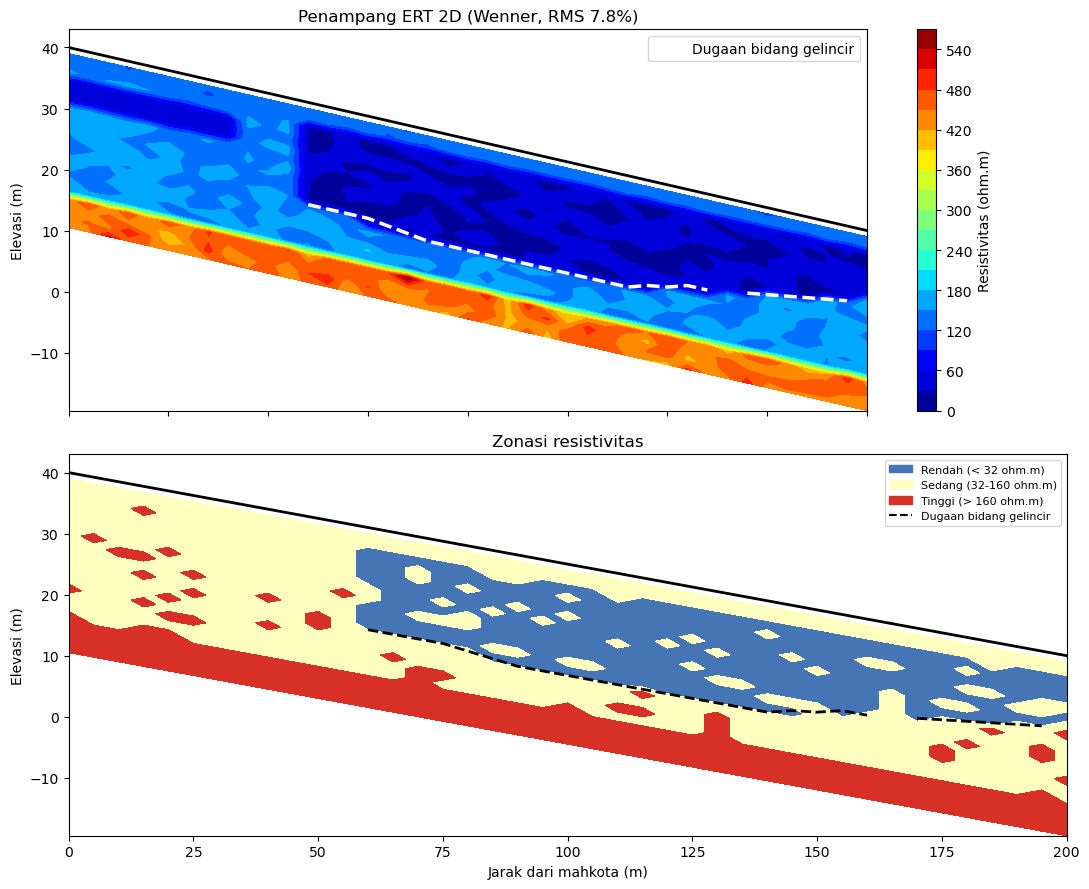

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from scipy.ndimage import label, uniform_filter1d
 
np.random.seed(3)
 
konfigurasi = "Wenner"
spasi_elektroda = 5.0            
panjang_lintasan = 200.0         
metode_inversi = "Robust/L2 (contoh)"
iterasi = 5
rms_error = 7.8                  
 
# Pengamatan retakan permukaan 
retakan_x = None                 # contoh: [20, 35, 60]
 
# pembangkit data contoh 
xs = np.arange(0, 201, 5.0)
zs = np.arange(1, 31, 1.5)
topo_df = pd.DataFrame({"x": xs, "elev": 40 - 0.15 * xs})
Xc, Zc = np.meshgrid(xs, zs)
z_slip_true = 7 + 8 * np.sin(np.pi * (xs - 20) / 180)          
rho_c = np.full(Xc.shape, 150.0)
rho_c[Zc <= 3] = 130.0                                         
zona_kond = (Zc > 3) & (Zc < z_slip_true[None, :] + 4) & (Xc >= 60)   
rho_c[zona_kond] = 30.0
tambalan = (Zc > 4) & (Zc < 9) & (Xc <= 40)                    
rho_c[tambalan] = 45.0
rho_c[Zc > 24] = 450.0                                         
rho_c = rho_c * np.exp(np.random.normal(0, 0.06, rho_c.shape))
grid = pd.DataFrame({"x": Xc.ravel(), "depth": Zc.ravel(), "rho": rho_c.ravel()})

# PEMERIKSAAN DATA
for k in ["x", "depth", "rho"]:
    if k not in grid.columns:
        raise SystemExit("Kolom '%s' tidak ada pada grid. Data tidak memadai." % k)
for k in ["x", "elev"]:
    if k not in topo_df.columns:
        raise SystemExit("Kolom '%s' tidak ada pada data topografi. Data tidak memadai." % k)
if (grid["rho"] <= 0).any() or grid["rho"].isna().any():
    raise SystemExit("Ada nilai resistivitas <= 0 atau kosong pada grid.")
 
x = np.sort(grid["x"].unique())
depth = np.sort(grid["depth"].unique())
if len(x) < 10 or len(depth) < 5:
    raise SystemExit("Grid terlalu kecil untuk interpretasi (minimal 10 kolom x 5 baris).")
rho = grid.pivot(index="depth", columns="x", values="rho").loc[depth, x].values     # (n_depth, n_x)
topo = np.interp(x, topo_df["x"].values, topo_df["elev"].values)
X, Z = np.meshgrid(x, depth)
elev = topo[None, :] - Z
dx = x[1] - x[0]
dz = depth[1] - depth[0]
 
print("Konfigurasi: %s | spasi elektroda: %.1f m | panjang lintasan: %.1f m" % (konfigurasi, spasi_elektroda, panjang_lintasan))
print("Inversi: %s | iterasi: %d | RMS: %.1f %%" % (metode_inversi, iterasi, rms_error))
print("Grid: %d kolom x %d baris (dx = %.1f m, dz = %.1f m)" % (len(x), len(depth), dx, dz))
if rms_error > 10:
    print("PERINGATAN: RMS error > 10% -> keandalan model rendah; seluruh interpretasi di bawah SANGAT tentatif.")
else:
    print("RMS error <= 10%: kecocokan data-model dapat diterima (bukan jaminan ketunggalan solusi).")
 

# (1) DESKRIPSI UMUM PENAMPANG (kiri = mahkota -> kanan = kaki)
print("\n=== (1) DESKRIPSI PENAMPANG (mahkota -> kaki) ===")
kemiringan = np.degrees(np.arctan((topo[0] - topo[-1]) / (x[-1] - x[0])))
print("Topografi: elevasi %.1f m (x=%d) -> %.1f m (x=%d); kemiringan rata-rata ~%.1f derajat." % (
    topo[0], x[0], topo[-1], x[-1], kemiringan))
bagian = np.array_split(np.arange(len(x)), 4)
for idx in bagian:
    kol = rho[:, idx]
    atas = kol[depth <= 5].mean()
    tengah = kol[(depth > 5) & (depth <= 15)].mean()
    bawah = kol[depth > 20].mean()
    print("x = %3d-%3d m | rho rata-rata: 0-5 m = %3.0f | 5-15 m = %3.0f | >20 m = %3.0f ohm.m | rentang total %.0f-%.0f" % (
        x[idx[0]], x[idx[-1]], atas, tengah, bawah, kol.min(), kol.max()))
 
# (2) ZONASI RESISTIVITAS (per komponen terhubung)
# Ambang: persentil 25 dan 75 data 
p25, p75 = np.percentile(rho, [25, 75])
zona = np.where(rho < p25, 1, np.where(rho > p75, 3, 2))
print("\n=== (2) ZONASI RESISTIVITAS ===")
print("Rendah: < %.0f ohm.m | Sedang: %.0f-%.0f ohm.m | Tinggi: > %.0f ohm.m" % (p25, p25, p75, p75))
print("Proporsi penampang: rendah %.0f%%, sedang %.0f%%, tinggi %.0f%%" % (
    (zona == 1).mean() * 100, (zona == 2).mean() * 100, (zona == 3).mean() * 100))
 
min_sel = 8      # komponen lebih kecil dari ini dianggap tidak bermakna
lab_rendah, n_rendah = label(zona == 1)
lab_tinggi, n_tinggi = label(zona == 3)
tafsir = {
    1: "dugaan zona jenuh air dan/atau lempung (AMBIGU: air vs lempung belum dapat dibedakan)",
    3: "dugaan batuan lebih kompak / material kering"}
for kode, lab, n, nama in [(1, lab_rendah, n_rendah, "RENDAH"), (3, lab_tinggi, n_tinggi, "TINGGI")]:
    komp = []
    for k in range(1, n + 1):
        sel = lab == k
        if sel.sum() >= min_sel:
            komp.append((sel.sum(), k))
    komp.sort(reverse=True)
    print("\nZona %s (%d komponen bermakna): %s" % (nama, len(komp), tafsir[kode]))
    for ukuran, k in komp[:4]:
        sel = lab == k
        print("  - x = %3.0f-%3.0f m, kedalaman %4.1f-%4.1f m, rho rata-rata %.0f ohm.m" % (
            X[sel].min(), X[sel].max(), Z[sel].min(), Z[sel].max(), rho[sel].mean()))
print("\nZona SEDANG: dugaan tanah lapuk/ pelapukan menengah, umumnya berada di antara dua zona di atas.")
 

# (3) DUGAAN BIDANG GELINCIR
mask_rendah = np.zeros(rho.shape, dtype=bool)
for k in range(1, n_rendah + 1):
    if (lab_rendah == k).sum() >= min_sel:
        mask_rendah = mask_rendah | (lab_rendah == k)
 
z_slip = np.full(len(x), np.nan)
kontras = np.full(len(x), np.nan)
for j in range(len(x)):
    baris = np.where(mask_rendah[:, j])[0]
    if len(baris) == 0:
        continue
    dasar = baris.max()
    if dasar + 2 >= len(depth):
        continue
    rho_dalam = rho[max(dasar - 1, 0):dasar + 1, j].mean()
    rho_bawah = rho[dasar + 1:dasar + 3, j].mean()
    if rho_bawah / rho_dalam >= 2.0:
        z_slip[j] = depth[dasar] + 0.5 * dz
        kontras[j] = rho_bawah / rho_dalam
 
valid = ~np.isnan(z_slip)
lab_seg, n_seg = label(valid)
z_halus = np.full(len(x), np.nan)
segmen = []
for s in range(1, n_seg + 1):
    idx = np.where(lab_seg == s)[0]
    if len(idx) >= 4:
        z_halus[idx] = uniform_filter1d(z_slip[idx], size=3, mode="nearest")
        segmen.append(idx)
 
print("\n=== (3) DUGAAN BIDANG GELINCIR (probabilistik) ===")
if len(segmen) == 0:
    print("Tidak ditemukan batas konduktif-resistif yang cukup menerus (>= ~20 m).")
    print("Bidang gelincir TIDAK dapat diduga dari penampang ini.")
else:
    print("Ditemukan %d segmen kandidat. Semuanya hanya DUGAAN, bukan bukti adanya bidang gelincir." % len(segmen))
    for no, idx in enumerate(segmen, 1):
        pj = (len(idx) - 1) * dx
        z_a = np.nanmin(z_halus[idx]); z_b = np.nanmax(z_halus[idx])
        kont = np.nanmean(kontras[idx])
        # kemiringan bidang terhadap topografi
        el_slip = topo[idx] - z_halus[idx]
        if len(idx) > 1:
            kem_slip = np.degrees(np.arctan((el_slip[0] - el_slip[-1]) / (x[idx[-1]] - x[idx[0]])))
            kem_topo = np.degrees(np.arctan((topo[idx[0]] - topo[idx[-1]]) / (x[idx[-1]] - x[idx[0]])))
        else:
            kem_slip = kem_topo = 0.0
        if pj >= 50 and kont >= 3:
            keyakinan = "relatif lebih meyakinkan"
        elif pj >= 30:
            keyakinan = "sedang"
        else:
            keyakinan = "lemah"
        print("Segmen %d: x = %.0f-%.0f m (%.0f m menerus), kedalaman ~%.1f-%.1f m, kontras rho ~%.1fx -> keyakinan %s" % (
            no, x[idx[0]], x[idx[-1]], pj, z_a, z_b, kont, keyakinan))
        print("   kemiringan bidang dugaan ~%.1f derajat vs lereng ~%.1f derajat (%s dengan topografi)" % (
            kem_slip, kem_topo, "sejajar" if abs(kem_slip - kem_topo) < 5 else "berbeda"))
    print("Alasan: dasar zona konduktif (kemungkinan jenuh/lempung) dengan kontras tajam ke material lebih resistif")
    print("        sering menjadi bidang lemah. Ini indikasi, bukan konfirmasi.")
 
# Pembanding retakan permukaan 
print("\nPembanding retakan permukaan:")
if retakan_x is None:
    print("  Data retakan tidak diberikan -> verifikasi silang dilewati.")
else:
    for rx in retakan_x:
        kol = np.argmin(np.abs(x - rx))
        ada_rendah = mask_rendah[:, kol].any()
        print("  Retakan x = %.0f m: %s" % (rx, "berdekatan dengan zona rho rendah" if ada_rendah else "TIDAK berasosiasi dengan zona rho rendah (catat ketidaksesuaian)"))
 
# (4) AMBIGUITAS & KETERBATASAN
print("\n=== (4) AMBIGUITAS & KETERBATASAN ===")
print("- Rho rendah dapat berasal dari air tanah ATAU lempung; butuh IP, uji lab, atau data kadar air.")
print("- Inversi non-unik dan dihaluskan; batas sesungguhnya bisa lebih tajam/ berbeda.")
print("- Resolusi turun dengan kedalaman; spasi %.0f m -> detail < ~%.0f m tidak terpecahkan." % (spasi_elektroda, spasi_elektroda / 2))
print("- Topografi dan efek 3D pada lereng dapat menimbulkan artefak.")
print("- Hasil bukan analisis stabilitas; faktor keamanan lereng TIDAK dihitung.")
 

# (5) REKOMENDASI VERIFIKASI LAPANGAN
print("\n=== (5) REKOMENDASI ===")
if len(segmen) > 0:
    semua = np.concatenate(segmen)
    z_dalam = np.nanmax(z_halus[semua]) + 5
    x_a = x[semua.min()]; x_b = x[semua.max()]
    x_t = x[semua[len(semua) // 2]]
    print("- Bor inti/ bor tangan di tiga titik: dekat mahkota segmen (x ~ %.0f m), tengah (x ~ %.0f m), dan kaki (x ~ %.0f m)," % (x_a, x_t, x_b))
    print("  sampai kedalaman minimal ~%.0f m untuk melihat kontak lapisan lunak-keras." % z_dalam)
else:
    print("- Karena tidak ada segmen terdeteksi, lakukan bor di zona rho rendah (lihat bagian 2) untuk pengecekan.")
print("- Uji geoteknik (SPT/CPT, kadar air, batas Atterberg) pada zona rho rendah dan di bawahnya.")
print("- Pasang inklinometer & piezometer; cocokkan posisi retakan dengan zona rho rendah.")
print("- Tambah lintasan paralel/silang untuk menguji kemenerusan lateral.")
 
fig, ax = plt.subplots(2, 1, figsize=(11, 9), sharex=True)
cs = ax[0].contourf(X, elev, rho, 20, cmap="jet")
ax[0].plot(x, topo, "k-", lw=2)
if len(segmen) > 0:
    for no, idx in enumerate(segmen):
        ax[0].plot(x[idx], topo[idx] - z_halus[idx], "w--", lw=2.5, label="Dugaan bidang gelincir" if no == 0 else None)
    ax[0].legend(loc="upper right")
plt.colorbar(cs, ax=ax[0], label="Resistivitas (ohm.m)")
ax[0].set_ylabel("Elevasi (m)")
ax[0].set_title("Penampang ERT 2D (%s, RMS %.1f%%)" % (konfigurasi, rms_error))
 
ax[1].contourf(X, elev, zona, levels=[0.5, 1.5, 2.5, 3.5], colors=["#4575b4", "#ffffbf", "#d73027"])
ax[1].plot(x, topo, "k-", lw=2)
if len(segmen) > 0:
    for idx in segmen:
        ax[1].plot(x[idx], topo[idx] - z_halus[idx], "k--", lw=2)
if retakan_x is not None:
    for rx in retakan_x:
        ax[1].plot([rx], [np.interp(rx, x, topo)], "kv", ms=9)
leg = [Patch(color="#4575b4", label="Rendah (< %.0f ohm.m)" % p25),
       Patch(color="#ffffbf", label="Sedang (%.0f-%.0f ohm.m)" % (p25, p75)),
       Patch(color="#d73027", label="Tinggi (> %.0f ohm.m)" % p75),
       Line2D([0], [0], color="k", ls="--", label="Dugaan bidang gelincir")]
ax[1].legend(handles=leg, loc="upper right", fontsize=8)
ax[1].set_xlabel("Jarak dari mahkota (m)")
ax[1].set_ylabel("Elevasi (m)")
ax[1].set_title("Zonasi resistivitas")
plt.tight_layout()
plt.savefig("hasil_prompt2_ERT.png", dpi=150)
plt.show()

---

## Prompt 3 — Pengolahan Data Gravitasi untuk Struktur Sesar

**Role:**
kita adalah seorang geofisikawan yang ahli dalam pengolahan dan interpretasi data gravitasi untuk eksplorasi struktur bawah permukaan.

**Task:**
Jelaskan tahapan koreksi data gravitasi hingga diperoleh anomali Bouguer lengkap, pisahkan anomali regional dan residual, lalu interpretasikan pola anomali residual sebagai indikasi struktur sesar atau cekungan.

**Context:**
Area studi berupa cekungan sedimen yang dibatasi dugaan sesar normal. Data diukur dengan gravimeter relatif pada grid titik dengan pengikatan ke titik base. Studi ini bersifat kajian awal untuk menentukan orientasi struktur.

**Input:**
Tabel titik ukur (koordinat, elevasi, pembacaan gravimeter, waktu), nilai gravitasi di base, dan densitas reduksi yang digunakan (mis. 2,67 g/cm³).

**Constraints:**
- Urutkan koreksi secara eksplisit: drift, pasang surut, lintang, free-air, Bouguer, dan terrain.
- Jangan menghasilkan angka koreksi yang tidak dapat dihitung dari input.
- Sebutkan metode pemisahan regional-residual yang dipakai dan alasannya.
- Tidak menyimpulkan jenis batuan hanya dari satu anomali.

**Output:**

(1) Alur pengolahan dari data mentah ke anomali Bouguer lengkap. 

(2) Deskripsi pola anomali (gradien, kelurusan, nilai tinggi dan rendah). 

(3) Interpretasi dugaan sesar dan cekungan. 

(4) Sensitivitas terhadap pilihan densitas dan metode pemisahan. 

(5) Saran data pendukung, misalnya seismik atau geologi permukaan.

**Quality criteria:**
Setiap koreksi dijelaskan tujuan dan rumus umumnya, hasil konsisten secara fisik (mis. gradien besar dikaitkan dengan batas kontras densitas), dan asumsi ditulis eksplisit.

**Optional verification:**
Lakukan uji sensitivitas sederhana dengan dua nilai densitas reduksi, lalu laporkan apakah kesimpulan struktur berubah.

=== (1) ALUR PENGOLAHAN ===
Jumlah titik: 150 | densitas reduksi: 2.67 g/cm3
1. Drift    : 0.0200 mGal/jam. D = (g_akhir - g_awal)/(t_akhir - t_awal) * (t - t_awal)
2. Pasut    : kolom 'tide' tidak ada -> TIDAK diterapkan (hitung dengan model Longman bila tersedia).
3. Lintang  : g_n = 978032.67715 (1 + 0.0053024 sin^2(phi) - 0.0000059 sin^2(2 phi)) mGal
4. Free-air : FAC = +0.3086 h (mGal; h dalam m), ditambahkan ke g_obs
5. Bouguer  : BC = 0.04193 rho h (mGal; rho g/cm3), dikurangkan; rho = 2.67
6. Terrain  : kolom 'terrain' tidak ada -> TIDAK diterapkan; CBA = SBA (catat sebagai keterbatasan).
   CBA = g_obs - g_n + FAC - BC + TC
        FAA    SBA    CBA
min   -8.79 -11.32 -11.32
max   11.54   6.03   6.03
mean   1.09  -2.75  -2.75
std    4.88   4.50   4.50

Metode regional-residual: trend surface polinomial orde-2 (kuadrat) dengan least squares,
dipilih karena sederhana, reprodusibel, dan cocok untuk tren regional yang landai di cekungan.

=== (2) POLA ANOMALI ===
CBA      : -11.32

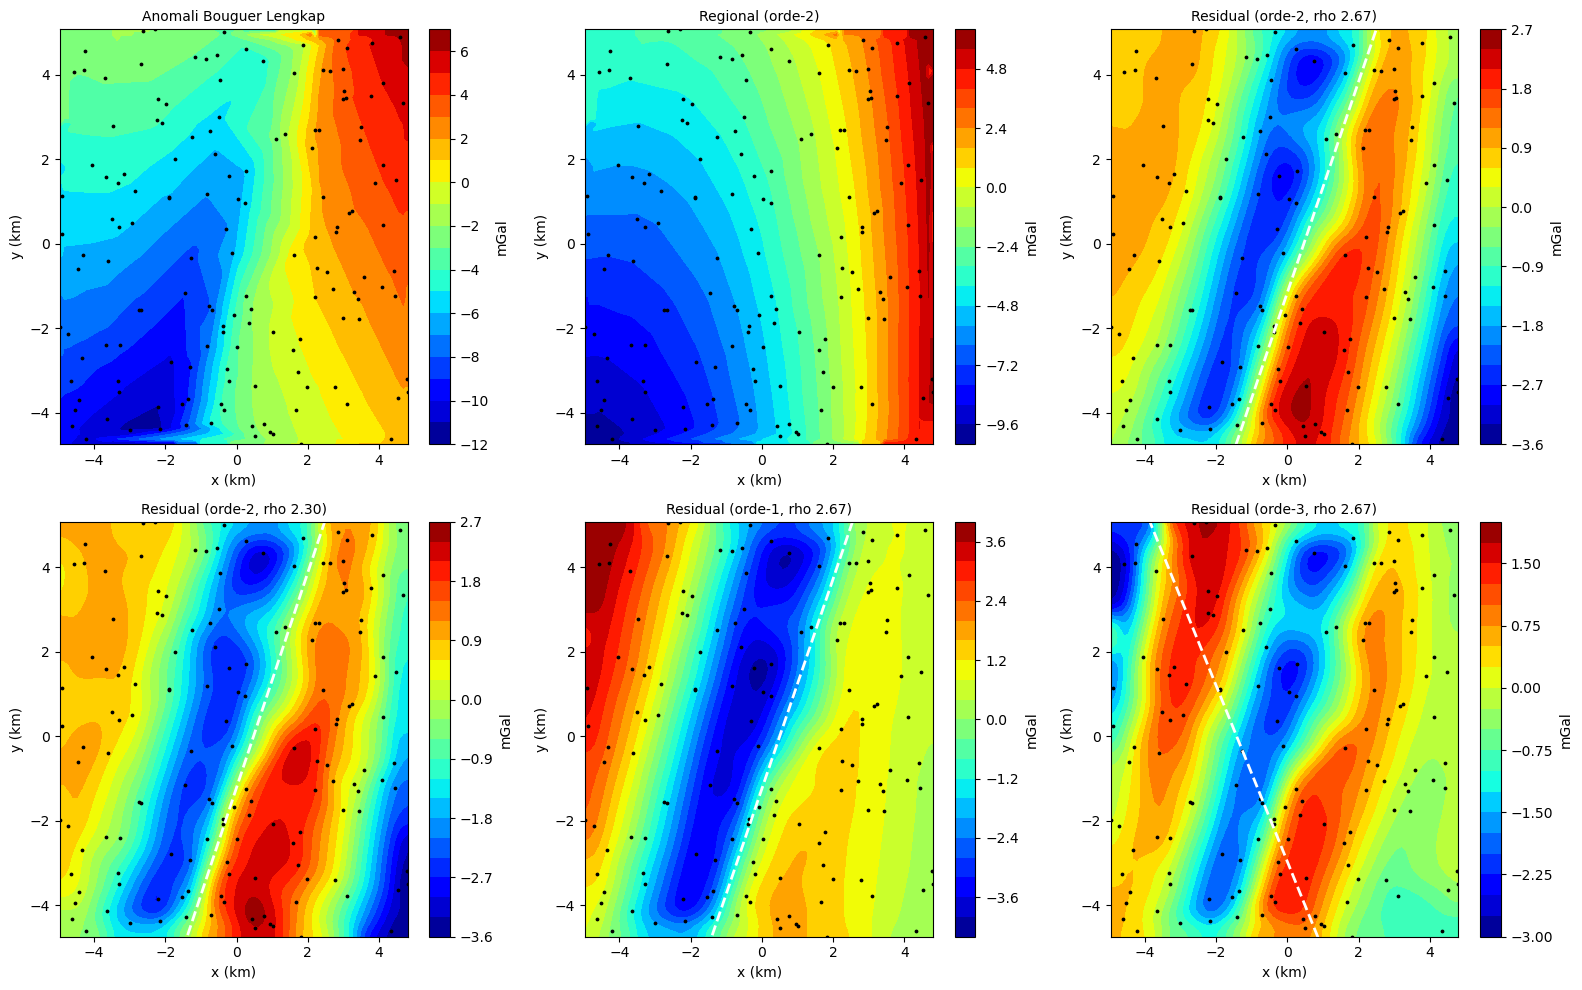

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter
 
np.random.seed(7)
 

densitas = 2.67                  # g/cm3, densitas reduksi
g_base_abs = 978100.00           # mGal, gravitasi absolut di base
baca_base_awal = 3000.00         # pembacaan alat di base, 
waktu_awal = 8.0                 # jam desimal
baca_base_akhir = 3000.17        # pembacaan alat di base, akhir survei (mGal)
waktu_akhir = 16.5
 
# --- pembangkit data contoh ---
n = 150
lon0, lat0 = 119.45, -5.15
x_t = np.random.uniform(-5, 5, n)                    # km
y_t = np.random.uniform(-5, 5, n)
lon = lon0 + x_t / (111.32 * np.cos(np.radians(lat0)))
lat = lat0 + y_t / 110.57
elev = np.random.uniform(5, 60, n)
waktu = np.sort(np.random.uniform(waktu_awal, waktu_akhir, n))
az_sesar = np.radians(20.0)                          # sesar contoh berarah N20E
jarak_tegak = x_t * np.cos(az_sesar) - y_t * np.sin(az_sesar)
# cekungan lokal di sisi barat sesar: -12 mGal di sesar, meluruh ke barat (skala ~2.5 km)
anom_true = -12 * np.exp(np.minimum(jarak_tegak, 0) / 2.5) * (1 - 1 / (1 + np.exp(-jarak_tegak / 0.5)))
regional_true = 0.8 * x_t + 0.5 * y_t                # tren regional linear contoh
phi_t = np.radians(lat)
g_n_t = 978032.67715 * (1 + 0.0053024 * np.sin(phi_t) ** 2 - 0.0000059 * np.sin(2 * phi_t) ** 2)
# g_obs = g_normal + anomali - FAC + BC   (gravitasi berkurang jika elevasi naik)
g_obs_t = g_n_t + anom_true + regional_true - 0.3086 * elev + 0.04193 * densitas * elev
drift_t = 0.02 * (waktu - waktu_awal)
baca = g_obs_t - g_base_abs + baca_base_awal + drift_t + np.random.normal(0, 0.05, n)
df = pd.DataFrame({"lon": lon, "lat": lat, "elev": elev, "baca": baca, "waktu": waktu})

 

# PEMERIKSAAN DATA
for k in ["lon", "lat", "elev", "baca", "waktu"]:
    if k not in df.columns:
        raise SystemExit("Kolom '%s' tidak ada pada tabel titik ukur. Data tidak memadai." % k)
df = df.dropna(subset=["lon", "lat", "elev", "baca", "waktu"]).reset_index(drop=True)
if len(df) < 30:
    raise SystemExit("Titik ukur terlalu sedikit (< 30) untuk pemisahan regional-residual yang layak.")
if waktu_akhir <= waktu_awal:
    raise SystemExit("Waktu akhir pembacaan base harus lebih besar dari waktu awal.")
if (df["waktu"].min() < waktu_awal) or (df["waktu"].max() > waktu_akhir):
    print("PERINGATAN: ada pembacaan di luar rentang waktu base awal-akhir; drift diekstrapolasi.")
ada_tide = "tide" in df.columns
ada_terrain = "terrain" in df.columns
if not ada_tide:
    df["tide"] = 0.0
if not ada_terrain:
    df["terrain"] = 0.0
n = len(df)
 

# (1) ALUR PENGOLAHAN
print("=== (1) ALUR PENGOLAHAN ===")
print("Jumlah titik: %d | densitas reduksi: %.2f g/cm3" % (n, densitas))
 
# 1. Drift 
laju_drift = (baca_base_akhir - baca_base_awal) / (waktu_akhir - waktu_awal)
df["drift"] = laju_drift * (df["waktu"] - waktu_awal)
print("1. Drift    : %.4f mGal/jam. D = (g_akhir - g_awal)/(t_akhir - t_awal) * (t - t_awal)" % laju_drift)
 
# 2. Pasang surut
if ada_tide:
    print("2. Pasut    : memakai kolom 'tide' dari input (mGal).")
else:
    print("2. Pasut    : kolom 'tide' tidak ada -> TIDAK diterapkan (hitung dengan model Longman bila tersedia).")
 
# Gravitasi observasi 
df["g_obs"] = g_base_abs + (df["baca"] - df["drift"] - df["tide"] - baca_base_awal)
 
# 3. Lintang (rumus GRS80 1980)
phi = np.radians(df["lat"])
df["g_n"] = 978032.67715 * (1 + 0.0053024 * np.sin(phi) ** 2 - 0.0000059 * np.sin(2 * phi) ** 2)
print("3. Lintang  : g_n = 978032.67715 (1 + 0.0053024 sin^2(phi) - 0.0000059 sin^2(2 phi)) mGal")
 
# 4. Free-air
df["FAC"] = 0.3086 * df["elev"]
print("4. Free-air : FAC = +0.3086 h (mGal; h dalam m), ditambahkan ke g_obs")
 
# 5. Bouguer sederhana
df["BC"] = 0.04193 * densitas * df["elev"]
print("5. Bouguer  : BC = 0.04193 rho h (mGal; rho g/cm3), dikurangkan; rho = %.2f" % densitas)
 
# 6. Terrain
if ada_terrain:
    print("6. Terrain  : memakai kolom 'terrain' (mGal) dari input.")
else:
    print("6. Terrain  : kolom 'terrain' tidak ada -> TIDAK diterapkan; CBA = SBA (catat sebagai keterbatasan).")
 
df["FAA"] = df["g_obs"] - df["g_n"] + df["FAC"]
df["SBA"] = df["FAA"] - df["BC"]
df["CBA"] = df["SBA"] + df["terrain"]
print("   CBA = g_obs - g_n + FAC - BC + TC")
print(df[["FAA", "SBA", "CBA"]].describe().round(2).loc[["min", "max", "mean", "std"]].to_string())
 
# koordinat lokal (km)
x = ((df["lon"] - df["lon"].mean()) * 111.32 * np.cos(np.radians(df["lat"].mean()))).values
y = ((df["lat"] - df["lat"].mean()) * 110.57).values
xi = np.linspace(x.min(), x.max(), 80)
yi = np.linspace(y.min(), y.max(), 80)
XI, YI = np.meshgrid(xi, yi)
dxg = xi[1] - xi[0]
 


# Kombinasi: densitas {2.30, densitas input} x orde polinomial {1, 2, 3}
rho_list = sorted(set([2.30, densitas]))
orde_list = [1, 2, 3]
hasil = {}
for rho_uji in rho_list:
    cba_uji = (df["g_obs"] - df["g_n"] + df["FAC"] - 0.04193 * rho_uji * df["elev"] + df["terrain"]).values
    for orde in orde_list:
        kolom = []
        for p in range(orde + 1):
            for q in range(orde + 1 - p):
                kolom.append(x**p * y**q)
        A = np.column_stack(kolom)
        koef, _, _, _ = np.linalg.lstsq(A, cba_uji, rcond=None)
        regional = A @ koef
        resid = cba_uji - regional
        # grid residual, halus, gradien horizontal
        g_lin = griddata((x, y), resid, (XI, YI), method="linear")
        g_nn = griddata((x, y), resid, (XI, YI), method="nearest")
        g_res = np.where(np.isnan(g_lin), g_nn, g_lin)
        g_s = gaussian_filter(g_res, 2)
        gy, gx = np.gradient(g_s, dxg, dxg)
        gh = np.sqrt(gx**2 + gy**2)
        gh[:4, :] = 0; gh[-4:, :] = 0; gh[:, :4] = 0; gh[:, -4:] = 0
        sel = gh > 0.7 * gh.max()
        px = XI[sel]; py = YI[sel]
        cx = px.mean(); cy = py.mean()
        _, _, vt = np.linalg.svd(np.column_stack([px - cx, py - cy]), full_matrices=False)
        azimut = np.degrees(np.arctan2(vt[0, 0], vt[0, 1])) % 180
        nx = np.cos(np.radians(azimut)); ny = -np.sin(np.radians(azimut))     # normal garis
        offset = cx * nx + cy * ny
        hasil[(rho_uji, orde)] = dict(cba=cba_uji, regional=regional, resid=resid, g_s=g_s, gh=gh,
                                      azimut=azimut, cx=cx, cy=cy, nx=nx, ny=ny, offset=offset,
                                      gmax=gh.max(), rmin=resid.min(), rmax=resid.max())
 
utama = hasil[(densitas, 2)]
print("\nMetode regional-residual: trend surface polinomial orde-2 (kuadrat) dengan least squares,")
print("dipilih karena sederhana, reprodusibel, dan cocok untuk tren regional yang landai di cekungan.")
 

# (2) POLA ANOMALI
res = utama["resid"]
i_min = np.argmin(res)
i_max = np.argmax(res)
print("\n=== (2) POLA ANOMALI ===")
print("CBA      : %.2f s.d. %.2f mGal" % (utama["cba"].min(), utama["cba"].max()))
print("Residual : %.2f s.d. %.2f mGal" % (res.min(), res.max()))
print("Residual rendah (kandidat cekungan): lon %.4f, lat %.4f (%.2f mGal)" % (df["lon"][i_min], df["lat"][i_min], res[i_min]))
print("Residual tinggi (kandidat tinggian): lon %.4f, lat %.4f (%.2f mGal)" % (df["lon"][i_max], df["lat"][i_max], res[i_max]))
print("Gradien horizontal maksimum: %.2f mGal/km" % utama["gmax"])
 

# (3) INTERPRETASI SESAR / CEKUNGAN
az = utama["azimut"]
nx_u = utama["nx"]; ny_u = utama["ny"]
s_jarak = (XI * nx_u + YI * ny_u) - utama["offset"]               # jarak bertanda tegak lurus garis (km)
rata_neg = utama["g_s"][s_jarak < -1.0].mean()
rata_pos = utama["g_s"][s_jarak > 1.0].mean()
if rata_neg < rata_pos:
    arah_basin = (np.degrees(np.arctan2(nx_u, ny_u)) + 180) % 360
    rendah, tinggi = rata_neg, rata_pos
else:
    arah_basin = np.degrees(np.arctan2(nx_u, ny_u)) % 360
    rendah, tinggi = rata_pos, rata_neg
mata_angin = ["utara", "timur laut", "timur", "tenggara", "selatan", "barat daya", "barat", "barat laut"]
nama_arah = mata_angin[int(((arah_basin + 22.5) % 360) // 45)]
 
# lebar zona gradien tinggi (> 50% maks) di dekat garis
dekat = (utama["gh"] > 0.5 * utama["gmax"]) & (np.abs(s_jarak) < 2.0)
lebar = np.percentile(s_jarak[dekat], 95) - np.percentile(s_jarak[dekat], 5) if dekat.sum() > 5 else np.nan
 
print("\n=== (3) INTERPRETASI ===")
print("Kelurusan gradien tinggi: berarah ~N%.0f E (azimut), melewati koordinat lokal (%.1f, %.1f) km." % (az, utama["cx"], utama["cy"]))
print("Lebar zona gradien tinggi (> 50%% maks): ~%.1f km (tegak lurus kelurusan)." % lebar)
print("Residual rata-rata kedua sisi: %.1f mGal (rendah) vs %.1f mGal (tinggi); selisih ~%.1f mGal." % (rendah, tinggi, tinggi - rendah))
print("Dugaan: sisi %s kelurusan adalah cekungan sedimen (residual rendah); sisi seberang relatif tinggian." % nama_arah)
print("Gradien besar dan lurus konsisten dengan batas kontras densitas, yaitu dugaan SESAR NORMAL yang")
print("turun ke arah %s (sisi cekungan). Ini hanya dugaan; jenis batuan tidak disimpulkan dari satu anomali." % nama_arah)
 

# (4) SENSITIVITAS DENSITAS & METODE PEMISAHAN
print("\n=== (4) UJI SENSITIVITAS ===")
baris = []
for rho_uji in rho_list:
    for orde in orde_list:
        h = hasil[(rho_uji, orde)]
        kor = np.corrcoef(h["resid"], utama["resid"])[0, 1]
        sel_az = abs(h["azimut"] - az)
        sel_az = min(sel_az, 180 - sel_az)
        baris.append([rho_uji, orde, h["rmin"], h["rmax"], h["azimut"], sel_az, h["offset"] - utama["offset"], kor])
tab = pd.DataFrame(baris, columns=["rho", "orde", "res_min", "res_max", "azimut", "d_azimut", "d_posisi(km)", "korelasi"])
print(tab.round(2).to_string(index=False))
maks_daz = tab["d_azimut"].max()
maks_dpos = tab["d_posisi(km)"].abs().max()
print("\nSimpangan maksimum terhadap kasus utama: arah %.0f derajat, posisi garis %.1f km." % (maks_daz, maks_dpos))
if maks_daz <= 15 and maks_dpos <= 1.0:
    print("-> Arah dan posisi struktur relatif STABIL terhadap pilihan densitas dan orde regional.")
else:
    print("-> Arah/posisi struktur BERUBAH cukup besar; kesimpulan struktur sensitif terhadap asumsi pengolahan.")
print("Catatan: perubahan densitas terutama mengubah amplitudo (korelasi tinggi), sedangkan orde regional")
print("         dapat menggeser/ menghaluskan gradien. Densitas lokal dari sampel batuan akan mengurangi ketidakpastian.")
 
# (5) SARAN DATA PENDUKUNG
print("\n=== (5) SARAN DATA PENDUKUNG ===")
print("- Seismik refleksi/refraksi tegak lurus kelurusan (N%.0f E) untuk konfirmasi bidang sesar dan kedalaman basement." % ((az + 90) % 180))
print("- Peta geologi permukaan dan DEM (kelurusan, gawir) untuk mengecek apakah jejak sesar muncul di permukaan.")
print("- Pengukuran densitas sampel batuan untuk menentukan densitas reduksi lokal.")
print("- Koreksi terrain dari DEM dan koreksi pasut Longman bila belum diterapkan.")
print("- Pemodelan 2D/3D gravitasi setelah ada data kendali (bor/seismik).")
 

cba_g = griddata((x, y), utama["cba"], (XI, YI), method="linear")
cba_g = np.where(np.isnan(cba_g), griddata((x, y), utama["cba"], (XI, YI), method="nearest"), cba_g)
reg_g = griddata((x, y), utama["regional"], (XI, YI), method="linear")
reg_g = np.where(np.isnan(reg_g), griddata((x, y), utama["regional"], (XI, YI), method="nearest"), reg_g)
panjang = max(x.max() - x.min(), y.max() - y.min())
 
fig, ax = plt.subplots(2, 3, figsize=(16, 10))
panel = [(ax[0, 0], cba_g, "Anomali Bouguer Lengkap", None),
         (ax[0, 1], reg_g, "Regional (orde-2)", None),
         (ax[0, 2], utama["g_s"], "Residual (orde-2, rho %.2f)" % densitas, utama),
         (ax[1, 0], hasil[(rho_list[0], 2)]["g_s"], "Residual (orde-2, rho %.2f)" % rho_list[0], hasil[(rho_list[0], 2)]),
         (ax[1, 1], hasil[(densitas, 1)]["g_s"], "Residual (orde-1, rho %.2f)" % densitas, hasil[(densitas, 1)]),
         (ax[1, 2], hasil[(densitas, 3)]["g_s"], "Residual (orde-3, rho %.2f)" % densitas, hasil[(densitas, 3)])]
for a, data, judul, h in panel:
    c = a.contourf(XI, YI, data, 20, cmap="jet")
    plt.colorbar(c, ax=a, label="mGal")
    a.scatter(x, y, c="k", s=3)
    if h is not None:
        t = np.array([-panjang, panjang])
        dx_l = np.sin(np.radians(h["azimut"])); dy_l = np.cos(np.radians(h["azimut"]))
        a.plot(h["cx"] + t * dx_l, h["cy"] + t * dy_l, "w--", lw=2)
    a.set_xlim(x.min(), x.max()); a.set_ylim(y.min(), y.max())
    a.set_title(judul, fontsize=10); a.set_xlabel("x (km)"); a.set_ylabel("y (km)")
plt.tight_layout()
plt.savefig("hasil_prompt3_gravitasi.png", dpi=150)
plt.show()

---

## Prompt 4 — Analisis Data Magnetik: Reduksi ke Kutub dan Deteksi Benda Termagnetisasi

**Role:**
kita adalah seorang geofisikawan eksplorasi mineral dengan keahlian dalam pengolahan dan interpretasi data magnetik.

**Task:**
Jelaskan cara mengolah data medan magnet total menjadi anomali magnetik, melakukan reduksi ke kutub, dan menginterpretasikan lokasi serta karakter benda penyebab anomali yang diduga intrusi atau zona mineralisasi.

**Context:**
Survei magnetik darat dilakukan di area prospek dengan batuan vulkanik dan dugaan intrusi. Daerah berada pada lintang rendah sehingga anomali cenderung tidak simetris terhadap sumbernya, dan reduksi ke kutub perlu dibahas dengan hati-hati.

**Input:**
Data medan magnet total (nT) beserta koordinat, data harian base station, nilai IGRF (inklinasi dan deklinasi) untuk lokasi dan tanggal survei.

**Constraints:**
- Sertakan koreksi variasi harian dan pengurangan IGRF.
- Jelaskan risiko ketidakstabilan reduksi ke kutub pada lintang rendah dan alternatifnya (mis. reduksi ke ekuator atau sinyal analitik).
- Jangan menyatakan adanya mineral tertentu; hanya karakter sumber magnetik.
- Hindari kesimpulan geometri sumber yang tegas tanpa data pendukung.

**Output:**

(1) Alur pengolahan dari data mentah ke anomali magnetik. 

(2) Perbedaan pola anomali sebelum dan sesudah reduksi. 

(3) Interpretasi posisi dan kedalaman perkiraan sumber. 

(4) Ketidakpastian, termasuk remanensi magnetik. 

(5) Rekomendasi survei lanjutan.

**Quality criteria:**
Arah dan parameter medan magnet bumi digunakan dengan benar, alternatif metode dibahas, dan kesimpulan dibatasi pada sifat magnetik sumber.

**Optional verification:**
Bandingkan hasil reduksi ke kutub dengan sinyal analitik; bila lokasi puncak anomali berbeda jauh, beri peringatan.

=== (1) ALUR PENGOLAHAN ===
Jumlah titik: 4096 | IGRF = 44500 nT, I = -20.0 deg, D = 1.0 deg
1. Variasi harian: B_k = B_obs - (B_base(t) - B_base_ref); B_base diinterpolasi ke waktu tiap titik.
   Rentang variasi harian: 15.6 nT (puncak ke puncak)
2. IGRF          : dT = B_k - B_IGRF; rata-rata dihapus untuk meniadakan offset level base.
3. Gridding      : 64 x 64 sel, dx = 25 m. Anomali: -175.8 s.d. 112.0 nT (std 12.3 nT)
4. RTP (FFT)     : filter = 1/[sin I + i cos I cos(D - theta)]^2
   Penguatan maks tanpa stabilisasi: 8.5x -> dibatasi 5x (lintang rendah: derau diperkuat).
   Alternatif dihitung sebagai pembanding: reduksi ke ekuator (RTE) dan sinyal analitik.
5. Sinyal analitik: |A| = sqrt(dT/dx^2 + dT/dy^2 + dT/dz^2), tidak bergantung arah magnetisasi.

=== (2) POLA ANOMALI SEBELUM & SESUDAH REDUKSI ===
Anomali asli  : maks +112.0 nT di (800, 875) m; min -175.8 nT di (800, 775) m
                pasangan positif-negatif terpisah 100 m (azimut 0 deg); |min|/maks = 1.57 -> dipolar/

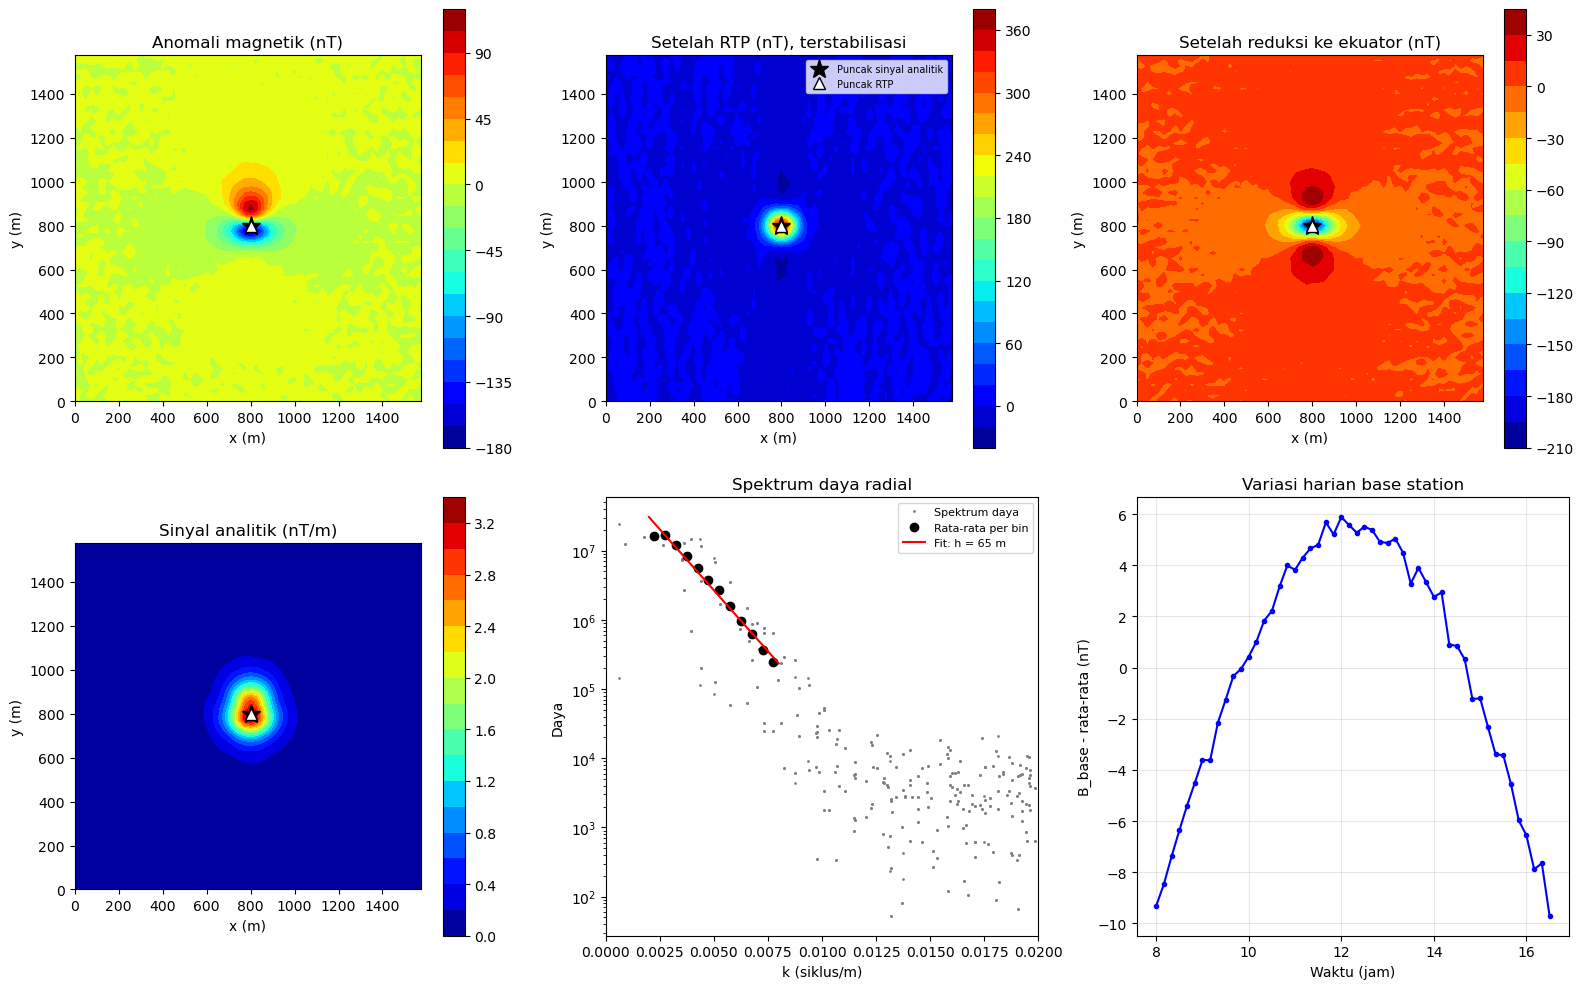

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter
 
np.random.seed(11)
 
igrf_total = 44500.0     # nT
inklinasi = -20.0        # derajat (lintang rendah, belahan bumi selatan)
deklinasi = 1.0          # derajat
dx_grid = 25.0           # m, spasi grid untuk pengolahan
 
# --- pembangkit data contoh (hapus jika memakai data lapangan) ---
xs = np.arange(0, 64) * 25.0
ys = np.arange(0, 64) * 25.0
Xc, Yc = np.meshgrid(xs, ys)
x0, y0, z0 = 800.0, 800.0, 100.0                      # sumber dipol contoh (kedalaman 100 m)
Ic = np.radians(inklinasi); Dc = np.radians(deklinasi)
f_e = np.cos(Ic) * np.sin(Dc)                          # timur arah medan
f_n = np.cos(Ic) * np.cos(Dc)                          # utara
f_u = -np.sin(Ic)                                      
rx = Xc - x0; ry = Yc - y0; rz = np.full(Xc.shape, z0)        
rr = np.sqrt(rx**2 + ry**2 + rz**2)
m_r = f_e * rx + f_n * ry + f_u * rz
Be = 3 * m_r * rx / rr**5 - f_e / rr**3
Bn = 3 * m_r * ry / rr**5 - f_n / rr**3
Bu = 3 * m_r * rz / rr**5 - f_u / rr**3
anom_true = 2e8 * (Be * f_e + Bn * f_n + Bu * f_u)     
waktu_pts = (8 + 8.0 * np.arange(64 * 64) / (64 * 64)).reshape(64, 64)   
def_harian = 15 * np.sin(np.pi * (waktu_pts - 8) / 8.5)                  
B_obs_c = igrf_total + 12.0 + anom_true + def_harian + np.random.normal(0, 1.0, Xc.shape)
df = pd.DataFrame({"x": Xc.ravel(), "y": Yc.ravel(), "B_obs": B_obs_c.ravel(), "waktu": waktu_pts.ravel()})
t_base = np.arange(8, 16.6, 1 / 6)                                       # base tiap 10 menit
base = pd.DataFrame({"waktu": t_base,
                     "B_base": igrf_total + 12.0 + 15 * np.sin(np.pi * (t_base - 8) / 8.5) + np.random.normal(0, 0.3, len(t_base))})

 

# PEMERIKSAAN DATA
for k in ["x", "y", "B_obs", "waktu"]:
    if k not in df.columns:
        raise SystemExit("Kolom '%s' tidak ada pada data magnetik. Data tidak memadai." % k)
for k in ["waktu", "B_base"]:
    if k not in base.columns:
        raise SystemExit("Kolom '%s' tidak ada pada data base station. Koreksi variasi harian tidak dapat dilakukan." % k)
df = df.dropna().reset_index(drop=True)
base = base.dropna().sort_values("waktu").reset_index(drop=True)
if len(df) < 200:
    raise SystemExit("Titik ukur terlalu sedikit (< 200) untuk pengolahan grid/FFT.")
if len(base) < 5:
    raise SystemExit("Data base station terlalu sedikit (< 5 pembacaan).")
if df["waktu"].min() < base["waktu"].min() or df["waktu"].max() > base["waktu"].max():
    print("PERINGATAN: waktu ukur di luar rentang base station; nilai base diekstrapolasi (kurang andal).")
if abs(inklinasi) > 90:
    raise SystemExit("Inklinasi harus berada di antara -90 dan 90 derajat.")
 

# (1) ALUR PENGOLAHAN
print("=== (1) ALUR PENGOLAHAN ===")
print("Jumlah titik: %d | IGRF = %.0f nT, I = %.1f deg, D = %.1f deg" % (len(df), igrf_total, inklinasi, deklinasi))
base_t = np.interp(df["waktu"].values, base["waktu"].values, base["B_base"].values)
base_ref = base["B_base"].mean()
df["B_koreksi"] = df["B_obs"] - (base_t - base_ref)
print("1. Variasi harian: B_k = B_obs - (B_base(t) - B_base_ref); B_base diinterpolasi ke waktu tiap titik.")
print("   Rentang variasi harian: %.1f nT (puncak ke puncak)" % (base["B_base"].max() - base["B_base"].min()))
df["anom"] = df["B_koreksi"] - igrf_total
print("2. IGRF          : dT = B_k - B_IGRF; rata-rata dihapus untuk meniadakan offset level base.")
 
# Grid reguler (interpolasi linear; tepi diisi nearest)
xg = np.arange(df["x"].min(), df["x"].max() + 0.5 * dx_grid, dx_grid)
yg = np.arange(df["y"].min(), df["y"].max() + 0.5 * dx_grid, dx_grid)
X, Y = np.meshgrid(xg, yg)
g_lin = griddata((df["x"], df["y"]), df["anom"], (X, Y), method="linear")
g_nn = griddata((df["x"], df["y"]), df["anom"], (X, Y), method="nearest")
anom = np.where(np.isnan(g_lin), g_nn, g_lin)
anom = anom - anom.mean()
ny, nx = anom.shape
print("3. Gridding      : %d x %d sel, dx = %.0f m. Anomali: %.1f s.d. %.1f nT (std %.1f nT)" % (
    nx, ny, dx_grid, anom.min(), anom.max(), anom.std()))
 
# Bilangan gelombang (rad/m); theta = azimut vektor gelombang dari utara
kx = 2 * np.pi * np.fft.fftfreq(nx, d=dx_grid)
ky = 2 * np.pi * np.fft.fftfreq(ny, d=dx_grid)
KX, KY = np.meshgrid(kx, ky)
K = np.sqrt(KX**2 + KY**2)
theta = np.arctan2(KX, KY)
Ir = np.radians(inklinasi); Dr = np.radians(deklinasi)
Theta = np.sin(Ir) + 1j * np.cos(Ir) * np.cos(Dr - theta)
 
# RTP: 1 / Theta^2 (magnetisasi induksi = arah medan bumi)
filt_rtp = 1.0 / Theta**2
gain_rtp = np.abs(filt_rtp)
gain_max = 5.0
skala = np.where(gain_rtp > gain_max, gain_max / gain_rtp, 1.0)
filt_rtp_stab = filt_rtp * skala
print("4. RTP (FFT)     : filter = 1/[sin I + i cos I cos(D - theta)]^2")
print("   Penguatan maks tanpa stabilisasi: %.1fx -> dibatasi %.0fx (lintang rendah: derau diperkuat)." % (gain_rtp.max(), gain_max))
print("   Alternatif dihitung sebagai pembanding: reduksi ke ekuator (RTE) dan sinyal analitik.")
 
# RTE: target I' = 0, D' = 0 -> filter = (i cos(theta))^2 / Theta^2 = -cos^2(theta)/Theta^2
filt_rte = -np.cos(theta) ** 2 / Theta**2
gain_rte = np.abs(filt_rte)
filt_rte_stab = filt_rte * np.where(gain_rte > gain_max, gain_max / gain_rte, 1.0)
 
F = np.fft.fft2(anom)
rtp = np.real(np.fft.ifft2(F * filt_rtp_stab))
rte = np.real(np.fft.ifft2(F * filt_rte_stab))
 
# Sinyal analitik (data dihaluskan ringan agar turunan tidak didominasi derau)
F_s = np.fft.fft2(gaussian_filter(anom, 1.0))
d_x = np.real(np.fft.ifft2(F_s * 1j * KX))
d_y = np.real(np.fft.ifft2(F_s * 1j * KY))
d_z = np.real(np.fft.ifft2(F_s * K))
sa = np.sqrt(d_x**2 + d_y**2 + d_z**2)
print("5. Sinyal analitik: |A| = sqrt(dT/dx^2 + dT/dy^2 + dT/dz^2), tidak bergantung arah magnetisasi.")
 

# (2) POLA SEBELUM & SESUDAH REDUKSI
i_max = np.unravel_index(np.argmax(anom), anom.shape)
i_min = np.unravel_index(np.argmin(anom), anom.shape)
sep = np.hypot(X[i_max] - X[i_min], Y[i_max] - Y[i_min])
az_sep = np.degrees(np.arctan2(X[i_max] - X[i_min], Y[i_max] - Y[i_min])) % 360
j_rtp = np.unravel_index(np.argmax(rtp), rtp.shape)
j_rtp_min = np.unravel_index(np.argmin(rtp), rtp.shape)
j_rte = np.unravel_index(np.argmax(np.abs(rte)), rte.shape)
j_sa = np.unravel_index(np.argmax(sa), sa.shape)
rasio_awal = abs(anom.min()) / anom.max()
rasio_rtp = abs(rtp.min()) / rtp.max()
amplif = np.abs(rtp).max() / np.abs(anom).max()
 
print("\n=== (2) POLA ANOMALI SEBELUM & SESUDAH REDUKSI ===")
print("Anomali asli  : maks %+.1f nT di (%.0f, %.0f) m; min %+.1f nT di (%.0f, %.0f) m" % (
    anom.max(), X[i_max], Y[i_max], anom.min(), X[i_min], Y[i_min]))
print("                pasangan positif-negatif terpisah %.0f m (azimut %.0f deg); |min|/maks = %.2f -> dipolar/asimetris." % (
    sep, az_sep, rasio_awal))
print("Setelah RTP   : maks %+.1f nT di (%.0f, %.0f) m; min %+.1f nT; |min|/maks = %.2f" % (
    rtp.max(), X[j_rtp], Y[j_rtp], rtp.min(), rasio_rtp))
if rasio_rtp < rasio_awal:
    print("lobus negatif relatif mengecil -> anomali lebih monopolar (pola sumber lebih sederhana).")
else:
    print(" lobus negatif TIDAK mengecil -> reduksi kurang berhasil (cek arah magnetisasi/ stabilitas filter).")
print(" amplitudo ekstrem berubah %.1fx terhadap anomali asli." % amplif)
if amplif > 3:
    print(" PERINGATAN: amplifikasi besar -> derau/artefak kemungkinan ikut diperkuat (khas lintang rendah).")
print("Setelah RTE   : ekstrem |nilai| %.1f nT di (%.0f, %.0f) m" % (np.abs(rte).max(), X[j_rte], Y[j_rte]))
print("Sinyal analitik: maks %.2f nT/m di (%.0f, %.0f) m" % (sa.max(), X[j_sa], Y[j_sa]))
 

# (3) POSISI & KEDALAMAN PERKIRAAN SUMBER
# (a) posisi: puncak sinyal analitik (utama), puncak RTP dan RTE (pembanding)
d_rtp_sa = np.hypot(X[j_rtp] - X[j_sa], Y[j_rtp] - Y[j_sa])
d_rte_sa = np.hypot(X[j_rte] - X[j_sa], Y[j_rte] - Y[j_sa])
 
# (b) kedalaman dari spektrum daya radial: ln P(k) ~ -4 pi h k  (k dalam siklus/m)
P = np.abs(F) ** 2
kr = K / (2 * np.pi)
kmin_fit, kmax_fit = 0.002, 0.008
sel_k = (kr >= kmin_fit) & (kr <= kmax_fit)
bins = np.linspace(kmin_fit, kmax_fit, 13)
kp = []
lp = []
for b in range(len(bins) - 1):
    sel = (kr >= bins[b]) & (kr < bins[b + 1])
    if sel.sum() > 0:
        kp.append(0.5 * (bins[b] + bins[b + 1]))
        lp.append(np.log(P[sel].mean()))
kp = np.array(kp); lp = np.array(lp)
koef, cov = np.polyfit(kp, lp, 1, cov=True)
h_spek = -koef[0] / (4 * np.pi)
h_spek_err = np.sqrt(cov[0, 0]) / (4 * np.pi)
 
# (c) kedalaman dari lebar sinyal analitik: sumber titik/dipol -> AS ~ (r^2 + h^2)^-2, r_1/2 = 0.644 h
setengah = sa >= 0.5 * sa.max()
r_half = np.sqrt(setengah.sum() * dx_grid**2 / np.pi)
h_sa = r_half / 0.644
 
# (d) bentuk sumber: sumbu utama area AS >= 50% maks
px = X[setengah]; py = Y[setengah]
_, sv, vt = np.linalg.svd(np.column_stack([px - px.mean(), py - py.mean()]), full_matrices=False)
elong = sv[0] / sv[1] if sv[1] > 0 else np.inf
az_el = np.degrees(np.arctan2(vt[0, 0], vt[0, 1])) % 180
 
print("\n=== (3) POSISI & KEDALAMAN SUMBER ===")
print("Posisi horizontal (puncak sinyal analitik): x = %.0f m, y = %.0f m" % (X[j_sa], Y[j_sa]))
print("Puncak RTP  : (%.0f, %.0f) m, selisih %.0f m dari sinyal analitik" % (X[j_rtp], Y[j_rtp], d_rtp_sa))
print("Puncak RTE  : (%.0f, %.0f) m, selisih %.0f m dari sinyal analitik" % (X[j_rte], Y[j_rte], d_rte_sa))
if d_rtp_sa <= 3 * dx_grid:
    print("-> RTP dan sinyal analitik KONSISTEN (selisih <= 3 sel): posisi horizontal sumber relatif andal.")
else:
    print("PERINGATAN: puncak RTP dan sinyal analitik berbeda > 3 sel (%.0f m)." % d_rtp_sa)
    print("            RTP mungkin tidak stabil atau ada remanensi; utamakan sinyal analitik.")
print("Kedalaman (spektrum daya, k = %.3f-%.3f siklus/m): %.0f +/- %.0f m" % (kmin_fit, kmax_fit, h_spek, 2 * h_spek_err))
print("Kedalaman (lebar sinyal analitik, asumsi sumber titik/dipol): %.0f m" % h_sa)
h_lo = min(h_spek, h_sa); h_hi = max(h_spek, h_sa)
print("Perkiraan kedalaman puncak sumber: ~%.0f - %.0f m (orde besar; bergantung asumsi geometri)." % (h_lo, h_hi))
if elong < 1.5:
    print("Bentuk anomali sinyal analitik: relatif kompak/ isometrik (rasio sumbu %.1f) -> karakter sumber terlokalisir." % elong)
else:
    print("Bentuk anomali sinyal analitik: memanjang (rasio sumbu %.1f) berarah ~N%.0f E -> kemungkinan sumber linear." % (elong, az_el))
print("Catatan: geometri sumber tidak disimpulkan tegas; hanya karakter magnetik (sumber termagnetisasi kuat & lokal).")
 

# (4) KETIDAKPASTIAN
print("\n=== (4) KETIDAKPASTIAN ===")
print("- Remanensi: bila arah magnetisasi berbeda dari medan bumi, RTP/RTE salah geser dan bentuk berubah.")
print("- Lintang rendah (|I| = %.0f deg): RTP tidak stabil; hasil bergantung batas penguatan (%.0fx) yang dipilih." % (abs(inklinasi), gain_max))
print("- Kedalaman dari spektrum dan lebar sinyal analitik berbeda (%.0f vs %.0f m): rentang dipakai sebagai ketidakpastian." % (h_spek, h_sa))
print("- Efek tepi grid FFT, interpolasi, dan derau memengaruhi turunan dan spektrum.")
print("- Hanya sifat magnetik yang disimpulkan; keberadaan mineral tertentu TIDAK dapat dipastikan.")
 

# (5) REKOMENDASI
print("\n=== (5) REKOMENDASI SURVEI LANJUTAN ===")
print("- Ukur suseptibilitas dan remanensi pada sampel batuan/ core untuk menguji asumsi magnetisasi induksi.")
print("- Survei rapat (spasi < %.0f m) dan profil melintang di sekitar (%.0f, %.0f) m; pertimbangkan survei pada ketinggian berbeda." % (
    dx_grid, X[j_sa], Y[j_sa]))
print("- Gabungkan dengan IP/resistivitas dan gravitasi, lalu lakukan pemodelan 2D/3D magnetik sebelum pengeboran.")
 

kurva_x = np.linspace(kmin_fit, kmax_fit, 50)
fig, ax = plt.subplots(2, 3, figsize=(16, 10))
panel = [(ax[0, 0], anom, "Anomali magnetik (nT)"),
         (ax[0, 1], rtp, "Setelah RTP (nT), terstabilisasi"),
         (ax[0, 2], rte, "Setelah reduksi ke ekuator (nT)"),
         (ax[1, 0], sa, "Sinyal analitik (nT/m)")]
for a, data, judul in panel:
    c = a.contourf(X, Y, data, 20, cmap="jet")
    plt.colorbar(c, ax=a)
    a.plot(X[j_sa], Y[j_sa], "k*", ms=14, label="Puncak sinyal analitik")
    a.plot(X[j_rtp], Y[j_rtp], "w^", ms=9, mec="k", label="Puncak RTP")
    a.set_title(judul); a.set_xlabel("x (m)"); a.set_ylabel("y (m)"); a.set_aspect("equal")
ax[0, 1].legend(loc="upper right", fontsize=7)
ax[1, 1].semilogy(kr[kr > 0].ravel()[::7], P[kr > 0].ravel()[::7], ".", ms=2, color="gray", label="Spektrum daya")
ax[1, 1].semilogy(kp, np.exp(lp), "ko", label="Rata-rata per bin")
ax[1, 1].semilogy(kurva_x, np.exp(np.polyval(koef, kurva_x)), "r-", label="Fit: h = %.0f m" % h_spek)
ax[1, 1].set_xlim(0, 0.02); ax[1, 1].set_xlabel("k (siklus/m)"); ax[1, 1].set_ylabel("Daya")
ax[1, 1].set_title("Spektrum daya radial"); ax[1, 1].legend(fontsize=8)
ax[1, 2].plot(base["waktu"], base["B_base"] - base["B_base"].mean(), "b.-")
ax[1, 2].set_xlabel("Waktu (jam)"); ax[1, 2].set_ylabel("B_base - rata-rata (nT)")
ax[1, 2].set_title("Variasi harian base station"); ax[1, 2].grid(alpha=.3)
plt.tight_layout()
plt.savefig("hasil_prompt4_magnetik.png", dpi=150)
plt.show()

---

## Prompt 5 — Seismik Refraksi untuk Kedalaman Batuan Dasar (Bedrock)

**Role:**
kita adalah seorang geofisikawan rekayasa yang berpengalaman dalam interpretasi seismik refraksi dangkal untuk kebutuhan pondasi bangunan.

**Task:**
Interpretasikan data waktu tempuh (travel time) gelombang P dari satu lintasan seismik refraksi untuk menentukan kecepatan tiap lapisan dan kedalaman batuan dasar, lalu tuliskan hasilnya sebagai narasi yang dapat dibaca oleh insinyur sipil.

**Context:**
Rencana pembangunan gedung di area dengan tanah lunak di atas batuan yang lebih keras. Insinyur membutuhkan estimasi awal kedalaman lapisan keras. Hasil ini bukan pengganti uji geoteknik langsung.

**Input:**
Tabel first-arrival time tiap geophone untuk beberapa shot point (maju dan mundur), jarak antar geophone, dan panjang lintasan.

**Constraints:**
- Gunakan metode yang disebutkan secara eksplisit (mis. intercept time atau reciprocal method) dan tulis langkah hitungnya.
- Nyatakan asumsi bahwa kecepatan bertambah terhadap kedalaman; sebutkan bahaya lapisan tersembunyi (hidden layer) dan inversi kecepatan.
- Tidak memberikan nilai daya dukung tanah.
- Bila data forward dan reverse tidak konsisten, laporkan alih-alih memaksakan satu model.

**Output:**

(1) Ringkasan kualitas data first-arrival. 

(2) Segmentasi kurva travel time menjadi lapisan. 

(3) Hasil kecepatan dan ketebalan tiap lapisan. 

(4) Estimasi kedalaman bedrock beserta rentang ketidakpastian. 

(5) Implikasi bagi perencanaan pondasi secara umum dan keterbatasannya.

**Quality criteria:**
Perhitungan dapat direproduksi dari data, satuan konsisten, ketidakpastian dilaporkan, dan bahasa mudah dipahami non-geofisikawan tanpa kehilangan ketepatan teknis.

**Optional verification:**
Hitung ulang kedalaman menggunakan data shot arah sebaliknya dan bandingkan; bila selisih besar, jelaskan kemungkinan penyebabnya (topografi, dip lapisan, atau kesalahan picking).

=== ASUMSI MODEL ===
- Dua lapisan datar (planar); batas lapisan tidak miring/bergelombang secara berarti.
- Kecepatan BERTAMBAH terhadap kedalaman (v2 > v1); tidak ada hidden layer maupun velocity inversion.
- Topografi diasumsikan datar.
- PERHATIAN: data yang dipakai adalah DATA CONTOH (sintetis, v1=400, v2=1800, h=6 m).
  Kecocokan hasil hanya membuktikan skrip bekerja, BUKAN kualitas hasil lapangan.

=== (1) KUALITAS DATA FIRST-ARRIVAL ===
Geophone: 24 | spasi 2.0 m | panjang lintasan 46.0 m | shot di x = [0.0, 22.0, 46.0]
Shot x=  0.0 arah kanan: 23 titik, waktu monoton naik: TIDAK (periksa picking)
Shot x= 22.0 arah kanan: 12 titik, waktu monoton naik: ya
Shot x= 22.0 arah kiri : 11 titik, waktu monoton naik: ya
Shot x= 46.0 arah kiri : 23 titik, waktu monoton naik: ya
Cek waktu resiprokal (selisih seharusnya < ~2 ms):
  shot 0 <-> shot 22: 40.86 ms vs 41.68 ms | selisih 0.82 ms 
  shot 0 <-> shot 46: 54.51 ms vs 54.69 ms | selisih 0.18 ms 
  shot 22 <-> shot 46: 41.59 ms vs 42.

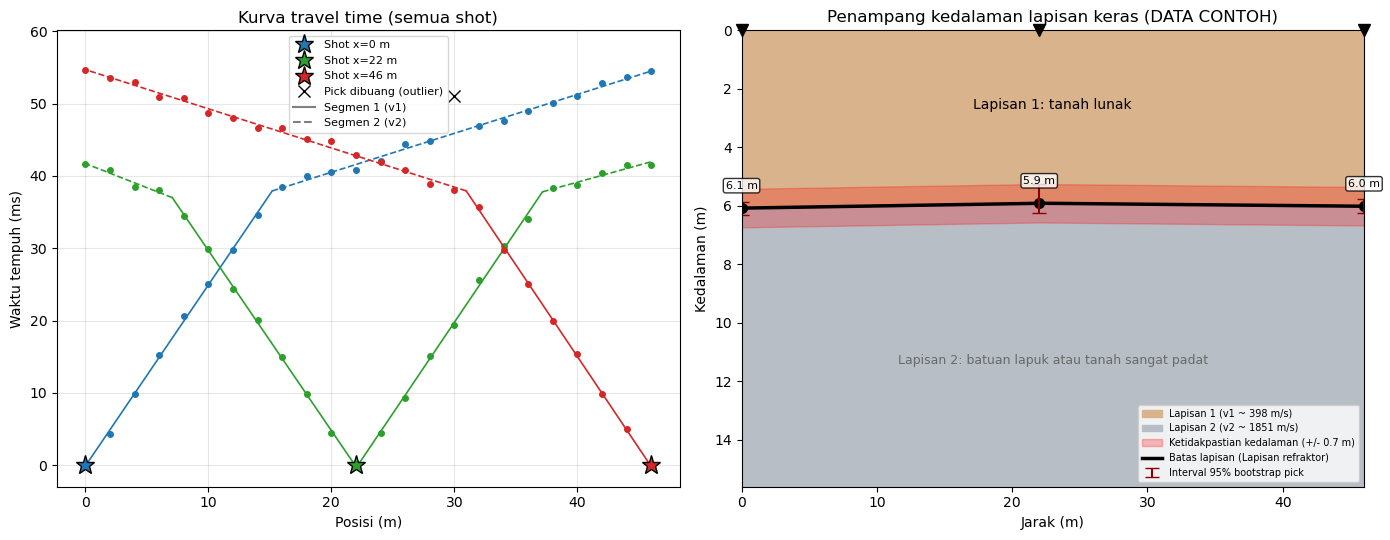

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
 
rng = np.random.default_rng(5)
 

DATA_DUMMY = True
FRAC_MODEL = 0.10      # komponen ketidakpastian model/resolusi spasi geophone (10% dari h), asumsi
 
if DATA_DUMMY:
    geo_x = np.arange(0, 47, 2.0)                  # 24 geophone, spasi 2 m
    shots = [0.0, 22.0, 46.0]                      # shot maju, tengah, mundur
    v1_c, v2_c, h_c = 400.0, 1800.0, 6.0
    ti_c = 2 * h_c * np.sqrt(v2_c**2 - v1_c**2) / (v1_c * v2_c)
    baris = []
    for sx in shots:
        for gx in geo_x:
            off = abs(gx - sx)
            t = min(off / v1_c, off / v2_c + ti_c) * 1000 + rng.normal(0, 0.5)   # ms
            baris.append([sx, gx, max(t, 0.0)])
    df = pd.DataFrame(baris, columns=["shot_x", "geo_x", "t_ms"])
    df.loc[(df.shot_x == 0) & (df.geo_x == 30), "t_ms"] += 6.0   # salah pick buatan (uji outlier)
else:
    df = pd.read_csv("first_arrival.csv")
 

# PEMERIKSAAN DATA
for k in ["shot_x", "geo_x", "t_ms"]:
    if k not in df.columns:
        raise SystemExit("Kolom '%s' tidak ada pada tabel first-arrival. Data tidak memadai." % k)
df = df.dropna().reset_index(drop=True)
geo_pos = np.sort(df["geo_x"].unique())
shots = sorted(df["shot_x"].unique())
if len(geo_pos) < 12:
    raise SystemExit("Jumlah geophone < 12; data tidak memadai untuk segmentasi 2 lapisan.")
if len(shots) < 2:
    raise SystemExit("Minimal 2 shot (maju dan mundur) diperlukan.")
spasi = np.median(np.diff(geo_pos))
panjang = geo_pos.max() - geo_pos.min()
 
c_shot = []; c_arah = []; d_list = []; t_list = []
for sx in shots:
    sub = df[df["shot_x"] == sx]
    for arah, tanda in [("kanan", 1), ("kiri", -1)]:
        off = tanda * (sub["geo_x"].values - sx)
        pilih = off > 0
        if pilih.sum() >= 8:
            urut = np.argsort(off[pilih])
            c_shot.append(sx)
            c_arah.append(arah)
            d_list.append(off[pilih][urut])
            t_list.append(sub["t_ms"].values[pilih][urut] / 1000.0)      # detik
nb = len(d_list)
if nb < 2:
    raise SystemExit("Cabang travel time terlalu sedikit (< 2 cabang dengan >= 8 titik).")
 
print("=== ASUMSI MODEL ===")
print("- Dua lapisan datar (planar); batas lapisan tidak miring/bergelombang secara berarti.")
print("- Kecepatan BERTAMBAH terhadap kedalaman (v2 > v1); tidak ada hidden layer maupun velocity inversion.")
print("- Topografi diasumsikan datar.")
if DATA_DUMMY:
    print("- PERHATIAN: data yang dipakai adalah DATA CONTOH (sintetis, v1=400, v2=1800, h=6 m).")
    print("  Kecocokan hasil hanya membuktikan skrip bekerja, BUKAN kualitas hasil lapangan.")
 
print("\n=== (1) KUALITAS DATA FIRST-ARRIVAL ===")
print("Geophone: %d | spasi %.1f m | panjang lintasan %.1f m | shot di x = %s" % (
    len(geo_pos), spasi, panjang, [float(s) for s in shots]))
 
for b in range(nb):
    naik = np.all(np.diff(t_list[b]) >= -0.002)
    print("Shot x=%5.1f arah %-5s: %2d titik, waktu monoton naik: %s" % (
        c_shot[b], c_arah[b], len(d_list[b]), "ya" if naik else "TIDAK (periksa picking)"))
 
print("Cek waktu resiprokal (selisih seharusnya < ~2 ms):")
ada_resip = False
for i in range(len(shots)):
    for j in range(i + 1, len(shots)):
        a = shots[i]; bb = shots[j]
        ta = df[(df["shot_x"] == a) & (np.isclose(df["geo_x"], bb))]["t_ms"]
        tb = df[(df["shot_x"] == bb) & (np.isclose(df["geo_x"], a))]["t_ms"]
        if len(ta) == 1 and len(tb) == 1:
            ada_resip = True
            sel = abs(ta.values[0] - tb.values[0])
            print("  shot %.0f <-> shot %.0f: %.2f ms vs %.2f ms | selisih %.2f ms %s" % (
                a, bb, ta.values[0], tb.values[0], sel, "" if sel <= 2 else "<- PERINGATAN: tidak cocok"))
if not ada_resip:
    print("  tidak ada pasangan shot-geophone resiprokal pada data.")
 

N_boot = 150
mask_list = [np.ones(len(d_list[b]), dtype=bool) for b in range(nb)]
sigma_list = [0.0005] * nb
final = [None] * nb
n_out = [0] * nb
hist_h = np.full((N_boot, nb), np.nan)
 
for it in range(N_boot + 2):
    for b in range(nb):
        m = mask_list[b]
        dd = d_list[b][m]
        tt = t_list[b][m].copy()
        if it >= 2:
            tt = tt + rng.normal(0, sigma_list[b], len(tt))
 
        sse_min = np.inf
        k_best = -1
        for k in range(3, len(dd) - 2):
            pa = np.polyfit(dd[:k], tt[:k], 1)
            pb = np.polyfit(dd[k:], tt[k:], 1)
            if pb[0] >= pa[0]:
                continue                     # v2 harus > v1
            sse = np.sum((tt[:k] - np.polyval(pa, dd[:k])) ** 2) + np.sum((tt[k:] - np.polyval(pb, dd[k:])) ** 2)
            if sse < sse_min:
                sse_min = sse
                k_best = k
                pa_b = pa
                pb_b = pb
        if k_best < 0:
            if it <= 1:
                raise SystemExit("Cabang shot x=%.1f arah %s: tidak ditemukan dua segmen dengan v2 > v1." % (c_shot[b], c_arah[b]))
            continue
 
        v1 = 1.0 / pa_b[0]
        v2 = 1.0 / pb_b[0]
        ti = pb_b[1]
        xc = (pb_b[1] - pa_b[1]) / (pa_b[0] - pb_b[0])
        h_ti = ti * v1 * v2 / (2 * np.sqrt(v2**2 - v1**2))
        h_xc = 0.5 * xc * np.sqrt((v2 - v1) / (v2 + v1))
 
        if it == 0:
            prediksi = np.minimum(np.polyval(pa_b, d_list[b]), np.polyval(pb_b, d_list[b]))
            res_all = t_list[b] - prediksi
            sig_rob = 1.4826 * np.median(np.abs(res_all - np.median(res_all)))
            batas = max(3 * sig_rob, 0.0015)
            mask_list[b] = np.abs(res_all) <= batas
            n_out[b] = int((~mask_list[b]).sum())
        elif it == 1:
            res_fit = np.concatenate([tt[:k_best] - np.polyval(pa_b, dd[:k_best]), tt[k_best:] - np.polyval(pb_b, dd[k_best:])])
            rmse = np.sqrt(np.mean(res_fit**2))
            sigma_list[b] = max(rmse, 0.0002)
            sse3 = np.inf
            v3 = np.nan
            if len(dd) >= 9:
                for k1 in range(3, len(dd) - 5):
                    for k2 in range(k1 + 3, len(dd) - 2):
                        qa = np.polyfit(dd[:k1], tt[:k1], 1)
                        qb = np.polyfit(dd[k1:k2], tt[k1:k2], 1)
                        qc = np.polyfit(dd[k2:], tt[k2:], 1)
                        if not (qa[0] > qb[0] > qc[0]):
                            continue
                        s3 = (np.sum((tt[:k1] - np.polyval(qa, dd[:k1])) ** 2) + np.sum((tt[k1:k2] - np.polyval(qb, dd[k1:k2])) ** 2)
                              + np.sum((tt[k2:] - np.polyval(qc, dd[k2:])) ** 2))
                        if s3 < sse3:
                            sse3 = s3
                            v3 = 1.0 / qc[0]
            final[b] = dict(k=k_best, pa=pa_b, pb=pb_b, v1=v1, v2=v2, ti=ti, xc=xc, h_ti=h_ti, h_xc=h_xc,
                            rmse=rmse, dd=dd, tt=tt, sse2=sse_min, sse3=sse3, v3=v3)
        else:
            hist_h[it - 2, b] = h_ti
 
print("\nRingkasan fit per cabang:")
for b in range(nb):
    f = final[b]
    print("  shot x=%5.1f %-5s | titik dipakai %2d, outlier dibuang %d | RMSE fit %.2f ms | intercept segmen-1 %.2f ms (ideal ~0)" % (
        c_shot[b], c_arah[b], len(f["dd"]), n_out[b], f["rmse"] * 1000, f["pa"][1] * 1000))
    if n_out[b] > 0:
        gone = d_list[b][~mask_list[b]]
        print("     titik dibuang pada offset %s m (residual > 3 sigma robust)" % np.round(gone, 1))
    if f["k"] < 3:
        print("     PERINGATAN: < 3 titik pada segmen 1 -> v1 kurang tertentukan")
 

# (2) SEGMENTASI
print("\n=== (2) SEGMENTASI KURVA TRAVEL TIME ===")
print("Langkah: tiap cabang dibagi 2 garis lurus (titik patah dicari dengan SSE minimum).")
print("         slope segmen 1 -> 1/v1, slope segmen 2 -> 1/v2, intercept segmen 2 = ti.")
for b in range(nb):
    f = final[b]
    print("Shot x=%5.1f %-5s: segmen 1 = offset %.0f-%.0f m (%d titik), segmen 2 = offset %.0f-%.0f m (%d titik); crossover xc = %.1f m" % (
        c_shot[b], c_arah[b], f["dd"][0], f["dd"][f["k"] - 1], f["k"], f["dd"][f["k"]], f["dd"][-1], len(f["dd"]) - f["k"], f["xc"]))
 

# (3) KECEPATAN & KETEBALAN
tab = pd.DataFrame({
    "Shot x": c_shot, "Arah": c_arah,
    "v1 (m/s)": [final[b]["v1"] for b in range(nb)],
    "v2 (m/s)": [final[b]["v2"] for b in range(nb)],
    "ti (ms)": [final[b]["ti"] * 1000 for b in range(nb)],
    "xc (m)": [final[b]["xc"] for b in range(nb)],
    "h intercept (m)": [final[b]["h_ti"] for b in range(nb)],
    "h crossover (m)": [final[b]["h_xc"] for b in range(nb)]})
print("\n=== (3) KECEPATAN & KETEBALAN ===")
print(tab.round(2).to_string(index=False))
 
f0 = final[0]
print("\nContoh langkah hitung (shot x=%.1f, arah %s):" % (c_shot[0], c_arah[0]))
print("  v1 = 1/slope1 = 1/%.6f = %.0f m/s" % (f0["pa"][0], f0["v1"]))
print("  v2 = 1/slope2 = 1/%.6f = %.0f m/s" % (f0["pb"][0], f0["v2"]))
print("  ti = intercept segmen 2 = %.5f s" % f0["ti"])
print("  h  = ti*v1*v2 / (2*sqrt(v2^2 - v1^2)) = %.5f*%.0f*%.0f / (2*sqrt(%.0f^2 - %.0f^2)) = %.2f m" % (
    f0["ti"], f0["v1"], f0["v2"], f0["v2"], f0["v1"], f0["h_ti"]))
print("  Pembanding crossover: h = (xc/2)*sqrt((v2-v1)/(v2+v1)) = (%.1f/2)*sqrt((%.0f-%.0f)/(%.0f+%.0f)) = %.2f m" % (
    f0["xc"], f0["v2"], f0["v1"], f0["v2"], f0["v1"], f0["h_xc"]))
 
i_f = None
i_r = None
for b in range(nb):
    if c_shot[b] == min(shots) and c_arah[b] == "kanan":
        i_f = b
    if c_shot[b] == max(shots) and c_arah[b] == "kiri":
        i_r = b
v1_rata = np.mean([final[b]["v1"] for b in range(nb)])
if i_f is not None and i_r is not None:
    v2_f = final[i_f]["v2"]; v2_r = final[i_r]["v2"]
    v2_rata = 2 / (1 / v2_f + 1 / v2_r)
    print("\nv2 maju = %.0f, v2 mundur = %.0f -> v2 sebenarnya (koreksi dip) = 2/(1/v2f + 1/v2r) = %.0f m/s" % (v2_f, v2_r, v2_rata))
else:
    v2_rata = np.mean([final[b]["v2"] for b in range(nb)])
    print("\nShot ujung maju/mundur tidak lengkap; v2 = rata-rata semua cabang = %.0f m/s" % v2_rata)
print("v1 rata-rata = %.0f m/s | rasio v2/v1 = %.1f" % (v1_rata, v2_rata / v1_rata))
 
# label lapisan 2 sesuai kecepatan
if v2_rata >= 3000:
    label_l2 = "Bedrock"
    ket_l2 = "batuan relatif segar/kompak"
elif v2_rata >= 1700:
    label_l2 = "Lapisan refraktor"
    ket_l2 = "batuan lapuk atau tanah sangat padat"
else:
    label_l2 = "Lapisan refraktor"
    ket_l2 = "tanah jenuh air/muka air tanah atau tanah padat; belum tentu batuan dasar"
 

# (4) KEDALAMAN + KETIDAKPASTIAN
print("\n=== (4) ESTIMASI KEDALAMAN LAPISAN KERAS ===")
h_shot = []; h_shot_lo = []; h_shot_hi = []
for sx in shots:
    idx = [b for b in range(nb) if c_shot[b] == sx]
    hs = np.mean([final[b]["h_ti"] for b in idx])
    boot = np.nanmean(hist_h[:, idx], axis=1)
    lo, hi = np.nanpercentile(boot, [2.5, 97.5])
    h_shot.append(hs); h_shot_lo.append(lo); h_shot_hi.append(hi)
    print("Di bawah shot x=%5.1f m: %.2f m (interval 95%% bootstrap pick saja: %.2f - %.2f m)" % (sx, hs, lo, hi))
 
h_all = np.mean([final[b]["h_ti"] for b in range(nb)])
pool = np.nanmean(hist_h, axis=1)
p_lo, p_hi = np.nanpercentile(pool, [2.5, 97.5])
sd_boot = np.nanstd(pool)
setengah_shot = 0.5 * (max(h_shot) - min(h_shot))
u_model = FRAC_MODEL * h_all
# tiga komponen digabung secara kuadrat (diasumsikan saling bebas)
u_tot = np.sqrt((1.96 * sd_boot) ** 2 + setengah_shot ** 2 + u_model ** 2)
rentang_lo = h_all - u_tot
rentang_hi = h_all + u_tot
print("\nKomponen ketidakpastian (m):")
print("  - derau picking (bootstrap, 95%%)    : +/- %.2f" % (1.96 * sd_boot))
print("  - variasi antar shot (lateral)       : +/- %.2f" % setengah_shot)
print("  - model & spasi geophone (asumsi %.0f%%): +/- %.2f" % (FRAC_MODEL * 100, u_model))
print("ESTIMASI KEDALAMAN (rata-rata semua cabang): %.1f m" % h_all)
print("Rentang ketidakpastian gabungan: %.1f - %.1f m (+/- %.1f m, ~%.0f%%)" % (
    rentang_lo, rentang_hi, u_tot, 100 * u_tot / h_all))
print("(interval bootstrap saja: %.2f - %.2f m; hanya mencerminkan derau pick, BUKAN ketidakpastian total)" % (p_lo, p_hi))
 
if i_f is not None and i_r is not None:
    hf = final[i_f]["h_ti"]; hr = final[i_r]["h_ti"]
    beda = abs(hf - hr) / (0.5 * (hf + hr)) * 100
    print("\nVerifikasi 1 (maju vs mundur): %.2f m vs %.2f m -> selisih %.1f %%" % (hf, hr, beda))
    if beda > 15:
        print("  PERINGATAN: selisih > 15 %. Kemungkinan: dip lapisan, topografi, atau kesalahan picking; jangan paksakan satu model.")
    else:
        print("  Konsisten (<= 15 %).")
 
beda_m = [abs(final[b]["h_ti"] - final[b]["h_xc"]) / final[b]["h_ti"] * 100 for b in range(nb)]
print("Verifikasi 2 (intercept vs crossover): selisih maks %.1f %% antar cabang" % max(beda_m))
if max(beda_m) > 15:
    print("  PERINGATAN: kedua metode berbeda > 15 %; periksa titik patah dan kemungkinan lapisan lain.")
 
ada3 = False
for b in range(nb):
    f = final[b]
    if np.isfinite(f["sse3"]) and f["sse3"] < 0.4 * f["sse2"] and f["v3"] > 1.2 * f["v2"]:
        ada3 = True
        print("Verifikasi 3: cabang shot x=%.1f %s menunjukkan indikasi segmen ke-3 (v ~ %.0f m/s)." % (c_shot[b], c_arah[b], f["v3"]))
if not ada3:
    print("Verifikasi 3: tidak ada indikasi kuat lapisan ke-3 pada data (bukan bukti bahwa lapisan lain tidak ada).")
 
rasio = panjang / h_all
print("Panjang lintasan / kedalaman = %.1f" % rasio)
if rasio < 3:
    print("  PERINGATAN: lintasan terlalu pendek relatif terhadap kedalaman; refraktor dalam kurang tercakup.")
else:
    print("  Lintasan cukup panjang untuk menjangkau refraktor (rasio >= 3).")
sedikit = [b for b in range(nb) if final[b]["k"] < 4]
if len(sedikit) > 0:
    print("PERINGATAN: spasi geophone %.1f m menyisakan < 4 titik pada segmen 1 di beberapa cabang -> v1 dan h kurang pasti." % spasi)
 

# (5) IMPLIKASI & KETERBATASAN
print("\n=== (5) IMPLIKASI BAGI PERENCANAAN PONDASI ===")
print("- Lapisan atas lebih lunak (v ~ %.0f m/s) setebal sekitar %.1f m (rentang %.1f - %.1f m) di atas lapisan lebih keras (v ~ %.0f m/s)." % (
    v1_rata, h_all, rentang_lo, rentang_hi, v2_rata))
print("- v2 ~ %.0f m/s lazim untuk %s." % (v2_rata, ket_l2))
if v2_rata < 3000:
    print("  Karena itu lapisan ini TIDAK otomatis dapat disebut batuan dasar segar; jenis materialnya perlu dipastikan dengan bor/uji langsung.")
print("- Informasi kedalaman ini dapat dipakai insinyur sebagai masukan awal dalam menimbang pilihan sistem pondasi (dangkal atau dalam);")
print("  skrip ini tidak memberi rekomendasi jenis pondasi.")
print("- Hasil BUKAN pengganti uji geoteknik (SPT/CPT/bor); daya dukung tanah TIDAK diberikan.")
print("Keterbatasan:")
print("- Asumsi: 2 lapisan planar dan kecepatan bertambah terhadap kedalaman.")
print("- Hidden layer (lapisan tipis/ kecepatan sedang) tidak terdeteksi sebagai first-arrival.")
print("- Velocity inversion (lapisan lunak di bawah lapisan keras) tidak dapat dikenali; kedalaman bisa meleset.")
print("- Variasi lateral hanya terwakili oleh beberapa shot; topografi dianggap datar.")
print("- Komponen ketidakpastian model (%.0f%%) adalah asumsi, bukan hasil pengukuran." % (FRAC_MODEL * 100))
print("- Rekomendasi: bor/ uji sondir di sekitar x = %s m untuk memverifikasi kedalaman." % [float(s) for s in shots])
 

# (6) NARASI UNTUK INSINYUR SIPIL
print("\n=== (6) NARASI UNTUK INSINYUR SIPIL ===")
konsisten = "konsisten" if (i_f is None or i_r is None or beda <= 15) else "TIDAK konsisten (perlu ditelaah ulang)"
print("Survei seismik refraksi sepanjang %.0f m (%d geophone, %d titik tembak) menunjukkan dua lapisan di bawah lintasan. "
      "Lapisan atas bersifat lunak dengan kecepatan gelombang P sekitar %.0f m/s, setebal sekitar %.1f m "
      "(perkiraan rentang %.1f - %.1f m). Di bawahnya terdapat lapisan yang lebih keras dengan kecepatan sekitar %.0f m/s." % (
          panjang, len(geo_pos), len(shots), v1_rata, h_all, rentang_lo, rentang_hi, v2_rata))
print("Kecepatan lapisan bawah tersebut lazim untuk %s, sehingga %s." % (
    ket_l2,
    "dapat dianggap mewakili batuan relatif segar" if v2_rata >= 3000
    else "belum dapat dipastikan sebagai batuan dasar tanpa pengecekan langsung"))
print("Pengukuran arah maju dan mundur %s, dan dua cara hitung (intercept time dan crossover distance) memberi selisih maksimum %.0f %%." % (
    konsisten, max(beda_m)))
print("Hasil ini mengandalkan asumsi dua lapisan datar dengan kecepatan yang bertambah terhadap kedalaman; lapisan tipis atau lapisan lunak "
      "di bawah lapisan keras tidak dapat dikenali metode ini. Angka kedalaman sebaiknya diverifikasi dengan bor atau sondir "
      "sebelum dipakai untuk perencanaan, dan hasil ini tidak memberikan nilai daya dukung tanah.")
if DATA_DUMMY:
    print("[CATATAN: narasi ini dihasilkan dari DATA CONTOH, bukan pengukuran lapangan.]")
 

warna = {}
pal = ["tab:blue", "tab:green", "tab:red", "tab:orange", "tab:purple"]
for i in range(len(shots)):
    warna[shots[i]] = pal[i % len(pal)]
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for b in range(nb):
    f = final[b]
    tanda = 1 if c_arah[b] == "kanan" else -1
    pos_all = c_shot[b] + tanda * d_list[b]
    ax[0].plot(pos_all[mask_list[b]], t_list[b][mask_list[b]] * 1000, "o", ms=4, color=warna[c_shot[b]])
    if n_out[b] > 0:
        ax[0].plot(pos_all[~mask_list[b]], t_list[b][~mask_list[b]] * 1000, "kx", ms=9)
    d1 = np.linspace(0, f["xc"], 20)
    d2 = np.linspace(f["xc"], f["dd"][-1], 20)
    ax[0].plot(c_shot[b] + tanda * d1, np.polyval(f["pa"], d1) * 1000, "-", color=warna[c_shot[b]], lw=1.2)
    ax[0].plot(c_shot[b] + tanda * d2, np.polyval(f["pb"], d2) * 1000, "--", color=warna[c_shot[b]], lw=1.2)
for sx in shots:
    ax[0].plot(sx, 0, "*", color=warna[sx], ms=14, mec="k", label="Shot x=%.0f m" % sx)
ax[0].plot([], [], "kx", ms=8, label="Pick dibuang (outlier)")
ax[0].plot([], [], "-", color="gray", label="Segmen 1 (v1)")
ax[0].plot([], [], "--", color="gray", label="Segmen 2 (v2)")
ax[0].set_xlabel("Posisi (m)"); ax[0].set_ylabel("Waktu tempuh (ms)")
ax[0].set_ylim(-3, max(max(t) for t in t_list) * 1000 * 1.1)
ax[0].set_title("Kurva travel time (semua shot)")
ax[0].legend(fontsize=8, loc="upper center"); ax[0].grid(alpha=.3)
 
xs_s = np.array(shots)
h_arr = np.array(h_shot)
xx = np.linspace(geo_pos.min(), geo_pos.max(), 200)
hh = np.interp(xx, xs_s, h_arr)
# ketidakpastian per titik: komponen gabungan dikurangi komponen lateral (sudah terlihat pada bentuk garis)
u_pt = np.sqrt((1.96 * sd_boot) ** 2 + u_model ** 2)
y_bawah = 100.0
 
# Lapisan 1 (cokelat) dan Lapisan 2 (abu-abu)
ax[1].fill_between(xx, 0, hh, color="#d9b38c", label="Lapisan 1 (v1 ~ %.0f m/s)" % v1_rata)
ax[1].fill_between(xx, hh, y_bawah, color="#b8bec6", label="Lapisan 2 (v2 ~ %.0f m/s)" % v2_rata)
# pita ketidakpastian mengikuti batas lapisan
ax[1].fill_between(xx, hh - u_pt, hh + u_pt, color="red", alpha=0.25,
                   label="Ketidakpastian kedalaman (+/- %.1f m)" % u_pt)
ax[1].plot(xx, hh, "k-", lw=2.5, label="Batas lapisan (%s)" % label_l2)
ax[1].plot(xs_s, h_arr, "ko", ms=7)
ax[1].errorbar(xs_s, h_arr, yerr=[h_arr - np.array(h_shot_lo), np.array(h_shot_hi) - h_arr],
               fmt="none", ecolor="darkred", capsize=5, label="Interval 95% bootstrap pick")
for sx_, h_ in zip(xs_s, h_arr):
    ax[1].annotate("%.1f m" % h_, (sx_, h_), textcoords="offset points", xytext=(0, 14),
                   ha="center", fontsize=8, bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8))
ax[1].plot(xs_s, np.zeros_like(xs_s), "v", color="k", ms=8, clip_on=False)
ax[1].text(geo_pos.mean(), 0.45 * np.mean(h_arr), "Lapisan 1: tanah lunak", ha="center", fontsize=10)
ax[1].text(geo_pos.mean(), np.mean(h_arr) * 1.9, "Lapisan 2: %s" % ket_l2.split(";")[0], ha="center", fontsize=9, color="dimgray")
ax[1].set_ylim(np.mean(h_arr) * 2.6, 0)
ax[1].set_xlim(geo_pos.min(), geo_pos.max())
ax[1].set_xlabel("Jarak (m)"); ax[1].set_ylabel("Kedalaman (m)")
ax[1].set_title("Penampang kedalaman lapisan keras" + (" (DATA CONTOH)" if DATA_DUMMY else ""))
ax[1].legend(loc="lower right", fontsize=7)
plt.tight_layout()
plt.savefig("hasil_prompt5_refraksi.png", dpi=150)
plt.show()